# 1. Extracción Homologada 2D (1 Canal) y Partición 70/15/15 por Paciente a HDF5
Extrae el corte axial central $z$ de cada uno de los 2,622 nódulos (3 >= mm) con consenso del 50% (clevel=0.50), ventana de [-1000, 400] HU, asignación de malignidad por densidad de probabilidad gaussiana del diámetro para resolver empates, parches negativos 1:1 de los 135 pacientes sin nódulos y partición paciente-disjunta 70/15/15 con semilla

In [1]:
# =====================================================================
# EXTRACCIÓN HOMOLOGADA 2D (1 CANAL, CLEVEL=0.50, SPLIT 70/15/15)
# =====================================================================
import os
import sys
import math
import random
import importlib.util
from types import ModuleType
from collections import Counter
import numpy as np
import h5py
from tqdm import tqdm
from sklearn.model_selection import train_test_split

# Parches de compatibilidad para pylidc en Python moderno
fake_pkg = ModuleType("pkg_resources")
class FakeDist: version = "0.2.3"
def get_distribution(name): return FakeDist()
def resource_filename(package_or_requirement, resource_name):
    spec = importlib.util.find_spec(package_or_requirement)
    return os.path.join(os.path.dirname(spec.origin), resource_name)
fake_pkg.get_distribution = get_distribution
fake_pkg.resource_filename = resource_filename
sys.modules["pkg_resources"] = fake_pkg

np.int = int
np.float = float
np.bool = bool

import pylidc as pl
from pylidc.utils import consensus

# Parámetros homologados con el trabajo de referencia
PATCH_SIZE = 96
HU_MIN, HU_MAX = -1000.0, 400.0
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Tabla 3-1: Media (mu) y Desviación Estándar (sigma) del diámetro en mm por clase (Grupo A)
GAUSS_PARAMS = {
    1: (5.819158, 2.359441),
    2: (5.577251, 2.885516),
    3: (6.174989, 3.012385),
    4: (9.962220, 4.506531),
    5: (17.409814, 5.566859)
}

def pdf_gaussiana(d, mu, sigma):
    return (1.0 / (sigma * math.sqrt(2.0 * math.pi))) * math.exp(-0.5 * ((d - mu) / sigma) ** 2)

def asignar_clase_malignidad(cluster, mask_3d, spacing_xyz):
    """
    Grupo A: mayoría simple entre radiólogos.
    Grupo B (empate): desempate mediante la PDF gaussiana del diámetro esférico equivalente (Ec. 3.1 y 3.2).
    """
    votos = [ann.malignancy for ann in cluster]
    conteo = Counter(votos)
    max_votos = max(conteo.values())
    clases_candidatas = [k for k, v in conteo.items() if v == max_votos]
    
    if len(clases_candidatas) == 1:
        return clases_candidatas[0], 'A'
    
    vol_voxeles = np.sum(mask_3d > 0)
    vol_mm3 = vol_voxeles * (spacing_xyz[0] * spacing_xyz[1] * spacing_xyz[2])
    diametro_mm = 2.0 * ((3.0 * vol_mm3) / (4.0 * math.pi)) ** (1.0 / 3.0)
    
    mejor_clase = max(clases_candidatas, key=lambda c: pdf_gaussiana(diametro_mm, *GAUSS_PARAMS[c]))
    return mejor_clase, 'B'

def normalizar_hu(img):
    img = np.clip(img, HU_MIN, HU_MAX)
    return ((img - HU_MIN) / (HU_MAX - HU_MIN)).astype(np.float32)

def extraer_parche_2d(vol_img, vol_msk, cy, cx, cz, size=96):
    """
    Extrae únicamente el corte axial central z en formato 2D: (1, 96, 96) para imagen y máscara.
    """
    H, W, D = vol_img.shape
    half = size // 2
    z_curr = max(0, min(D - 1, cz))
    
    corte_img = vol_img[:, :, z_curr][np.newaxis, :, :] # (1, H, W)
    corte_msk = vol_msk[:, :, z_curr][np.newaxis, :, :] # (1, H, W)
    
    pad_y0 = max(0, half - cy)
    pad_y1 = max(0, (cy + half) - H)
    pad_x0 = max(0, half - cx)
    pad_x1 = max(0, (cx + half) - W)
    
    if pad_y0 > 0 or pad_y1 > 0 or pad_x0 > 0 or pad_x1 > 0:
        corte_img = np.pad(corte_img, ((0, 0), (pad_y0, pad_y1), (pad_x0, pad_x1)), mode='constant', constant_values=0)
        corte_msk = np.pad(corte_msk, ((0, 0), (pad_y0, pad_y1), (pad_x0, pad_x1)), mode='constant', constant_values=0)
        cy += pad_y0
        cx += pad_x0
        
    parche_img = corte_img[:, cy - half : cy + half, cx - half : cx + half]
    parche_msk = corte_msk[:, cy - half : cy + half, cx - half : cx + half]
    return parche_img.astype(np.float32), parche_msk.astype(np.float32)

ruta_h5_2d = 'D:/U/aprendiendoMachin/dataset_lidc_homologado_2d.h5'

if os.path.exists(ruta_h5_2d):
    print(f"[!] El archivo {ruta_h5_2d} ya existe. Saltando extracción.")
else:
    scans = pl.query(pl.Scan).all()
    pacientes_dict = {}
    for s in scans:
        pacientes_dict.setdefault(s.patient_id, []).append(s)
        
    lista_pids = sorted(list(pacientes_dict.keys()))
    tiene_nodulo = [1 if any(len(s.annotations) > 0 for s in pacientes_dict[pid]) else 0 for pid in lista_pids]
    
    # División 70 / 15 / 15 estratificada por paciente (Semilla 42)
    pids_train, pids_temp, _, y_temp_p = train_test_split(
        lista_pids, tiene_nodulo, test_size=0.30, random_state=SEED, stratify=tiene_nodulo
    )
    pids_val, pids_test = train_test_split(
        pids_temp, test_size=0.50, random_state=SEED, stratify=y_temp_p
    )
    
    conjuntos_pids = {'train': set(pids_train), 'val': set(pids_val), 'test': set(pids_test)}
    print(f"Pacientes (70/15/15) -> Train: {len(pids_train)} | Val: {len(pids_val)} | Test: {len(pids_test)}")
    
    datos = {s: {'imgs': [], 'msks': [], 'det_lbl': [], 'mal_cls': [], 'grupo': []} for s in ['train', 'val', 'test']}
    
    for pid in tqdm(lista_pids, desc="Extrayendo parches 2D (96x96)"):
        split_actual = 'train' if pid in conjuntos_pids['train'] else ('val' if pid in conjuntos_pids['val'] else 'test')
        
        for scan in pacientes_dict[pid]:
            try:
                vol_hu = scan.to_volume()
                vol_norm = normalizar_hu(vol_hu)
                spacing = (scan.pixel_spacing, scan.pixel_spacing, scan.slice_thickness)
                clusters = scan.cluster_annotations()
                
                if len(clusters) > 0:
                    mask_vol_global = np.zeros_like(vol_norm, dtype=np.float32)
                    nodulos_info = []
                    
                    for cluster in clusters:
                        c_mask, c_bbox, _ = consensus(cluster, clevel=0.50)
                        if np.sum(c_mask) == 0:
                            continue
                        mask_vol_global[c_bbox][c_mask] = 1.0
                        clase_5, grp = asignar_clase_malignidad(cluster, c_mask, spacing)
                        
                        cy = (c_bbox[0].start + c_bbox[0].stop) // 2
                        cx = (c_bbox[1].start + c_bbox[1].stop) // 2
                        cz = (c_bbox[2].start + c_bbox[2].stop) // 2
                        nodulos_info.append((cy, cx, cz, clase_5, 1 if grp == 'A' else 2))
                        
                    for cy, cx, cz, clase_5, grp_id in nodulos_info:
                        p_img, p_msk = extraer_parche_2d(vol_norm, mask_vol_global, cy, cx, cz, PATCH_SIZE)
                        datos[split_actual]['imgs'].append(p_img)
                        datos[split_actual]['msks'].append(p_msk)
                        datos[split_actual]['det_lbl'].append(1.0)
                        datos[split_actual]['mal_cls'].append(clase_5) # 1,2=Benigno | 3=Indet | 4,5=Maligno
                        datos[split_actual]['grupo'].append(grp_id)
                else:
                    # Pacientes sin nódulos: extraemos parches sanos para relación ~1:1 en Etapa 1
                    H, W, D = vol_norm.shape
                    mask_vacia = np.zeros_like(vol_norm, dtype=np.float32)
                    for _ in range(19):
                        cz = random.randint(D // 4, 3 * D // 4)
                        cy = random.randint(PATCH_SIZE, H - PATCH_SIZE)
                        cx = random.randint(PATCH_SIZE, W - PATCH_SIZE)
                        p_img, p_msk = extraer_parche_2d(vol_norm, mask_vacia, cy, cx, cz, PATCH_SIZE)
                        datos[split_actual]['imgs'].append(p_img)
                        datos[split_actual]['msks'].append(p_msk)
                        datos[split_actual]['det_lbl'].append(0.0)
                        datos[split_actual]['mal_cls'].append(0)
                        datos[split_actual]['grupo'].append(0)
            except Exception:
                continue

    with h5py.File(ruta_h5_2d, 'w') as h5f:
        for split in ['train', 'val', 'test']:
            grp = h5f.create_group(split)
            grp.create_dataset('imagenes', data=np.array(datos[split]['imgs'], dtype=np.float32), compression="gzip")
            grp.create_dataset('mascaras', data=np.array(datos[split]['msks'], dtype=np.float32), compression="gzip")
            grp.create_dataset('det_lbl',  data=np.array(datos[split]['det_lbl'], dtype=np.float32))
            grp.create_dataset('mal_cls',  data=np.array(datos[split]['mal_cls'], dtype=np.int32))
            grp.create_dataset('grupo',    data=np.array(datos[split]['grupo'], dtype=np.int32))
            print(f"[{split.upper()}] Total parches 2D guardados: {len(datos[split]['imgs'])}")
    print(f"[✓] Compilación HDF5 2D finalizada en: {ruta_h5_2d}")

[!] El archivo D:/U/aprendiendoMachin/dataset_lidc_homologado_2d.h5 ya existe. Saltando extracción.


# 2. DataLoaders 2D desde HDF5 (Sin Saturar RAM)
DataLoaders 2D desde HDF5 (Sin Saturar RAM)

Etapa 1: Segmentación y detección de presencia de nódulo sobre todos los parches

Etapa 2: Clasificación de malignidad sobre nódulos con clases 1-2 Benignos vs. 4-5 Malignos, excluyendo la clase 3 indeterminada

In [2]:
# =====================================================================
# DATALOADERS 2D HOMOLOGADOS (ETAPA 1 Y ETAPA 2)
# =====================================================================
import torch
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dir_pesos_homologados = 'D:/U/aprendiendoMachin/Modelos_Homologados_2D'
os.makedirs(dir_pesos_homologados, exist_ok=True)

class LIDCHomologado2DDataset(Dataset):
    def __init__(self, ruta_h5, split='train', solo_malignidad=False):
        self.ruta_h5 = ruta_h5
        self.split = split
        self.solo_malignidad = solo_malignidad
        self.h5_file = None
        
        with h5py.File(self.ruta_h5, 'r') as f:
            clases_mal = f[self.split]['mal_cls'][:]
            if self.solo_malignidad:
                # Etapa 2: Solo nódulos Benignos (1, 2) y Malignos (4, 5). Excluye Indeterminados (3) y Sanos (0)
                self.indices = np.where(np.isin(clases_mal, [1, 2, 4, 5]))[0]
            else:
                # Etapa 1: Todos los parches (Positivos 1..5 y Negativos 0)
                self.indices = np.arange(len(clases_mal))

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        if self.h5_file is None:
            self.h5_file = h5py.File(self.ruta_h5, 'r')
            
        real_idx = self.indices[idx]
        grp = self.h5_file[self.split]
        
        img = torch.from_numpy(grp['imagenes'][real_idx]).float() # (1, 96, 96)
        msk = torch.from_numpy(grp['mascaras'][real_idx]).float() # (1, 96, 96)
        det_lbl = torch.tensor([grp['det_lbl'][real_idx]], dtype=torch.float32)
        mal_c = int(grp['mal_cls'][real_idx])
        
        # Etiqueta binaria de malignidad: 1.0 si es clase 4 o 5 (Maligno), 0.0 si es 1 o 2 (Benigno)
        mal_bin = 1.0 if mal_c in [4, 5] else 0.0
        mal_lbl = torch.tensor([mal_bin], dtype=torch.float32)
        
        return img, msk, det_lbl, mal_lbl, mal_c

# Cargadores para Etapa 1 (Segmentación y Detección)
train_ds_e1 = LIDCHomologado2DDataset(ruta_h5_2d, 'train', solo_malignidad=False)
val_ds_e1   = LIDCHomologado2DDataset(ruta_h5_2d, 'val',   solo_malignidad=False)
test_ds_e1  = LIDCHomologado2DDataset(ruta_h5_2d, 'test',  solo_malignidad=False)

train_loader_e1 = DataLoader(train_ds_e1, batch_size=16, shuffle=True,  num_workers=0, pin_memory=True)
val_loader_e1   = DataLoader(val_ds_e1,   batch_size=16, shuffle=False, num_workers=0, pin_memory=True)
test_loader_e1  = DataLoader(test_ds_e1,  batch_size=16, shuffle=False, num_workers=0, pin_memory=True)

# Cargadores para Etapa 2 (Clasificación de Malignidad: Benigno vs. Maligno)
train_ds_e2 = LIDCHomologado2DDataset(ruta_h5_2d, 'train', solo_malignidad=True)
val_ds_e2   = LIDCHomologado2DDataset(ruta_h5_2d, 'val',   solo_malignidad=True)
test_ds_e2  = LIDCHomologado2DDataset(ruta_h5_2d, 'test',  solo_malignidad=True)

train_loader_e2 = DataLoader(train_ds_e2, batch_size=32, shuffle=True,  num_workers=0, pin_memory=True)
val_loader_e2   = DataLoader(val_ds_e2,   batch_size=32, shuffle=False, num_workers=0, pin_memory=True)
test_loader_e2  = DataLoader(test_ds_e2,  batch_size=32, shuffle=False, num_workers=0, pin_memory=True)

print(f"Etapa 1 (Seg/Det) -> Train: {len(train_ds_e1)} | Val: {len(val_ds_e1)} | Test: {len(test_ds_e1)}")
print(f"Etapa 2 (Malign.) -> Train: {len(train_ds_e2)} | Val: {len(val_ds_e2)} | Test: {len(test_ds_e2)}")

Etapa 1 (Seg/Det) -> Train: 3158 | Val: 632 | Test: 762
Etapa 2 (Malign.) -> Train: 978 | Val: 186 | Test: 213


# 3. Arquitecturas (in_channels=1) con Incorporación de Descriptores Morfológicos
Clases UNet, CBAM, ModCBAM y TransUNet (in_channels=1), añadiendo la extracción de los 4 descriptores morfológicos (V área normalizada, e_a elongación/anisotropía, e_s circularidad/esfericidad y u (la u con un palito y simbolo de la ñ arriba) asimetría) sobre la máscara predicha para concatenarlos al vector de características (1024 + 4 = 1028) en el cabezal de clasificación

## Extractor de Descriptores Morfológicos 2D

In [3]:
# =====================================================================
# DESCRIPTORES MORFOLÓGICOS (HOMOLOGACIÓN ETAPA 2)
# =====================================================================
import torch
import torch.nn as nn

def calcular_descriptores_forma_2d(logits_mask):
    """
    Calcula los 4 descriptores geométricos a partir de la máscara binaria predicha (Hard Mask):
    [Área normalizada, Anisotropía, Esfericidad/Compacidad, Asimetría espacial]
    """
    with torch.no_grad():
        hard_mask = (torch.sigmoid(logits_mask) > 0.5).float()  # (B, 1, H, W)
        B, _, H, W = hard_mask.shape
        descriptores = torch.zeros((B, 4), dtype=logits_mask.dtype, device=logits_mask.device)
        
        y_grid, x_grid = torch.meshgrid(
            torch.arange(H, device=logits_mask.device, dtype=torch.float32),
            torch.arange(W, device=logits_mask.device, dtype=torch.float32),
            indexing='ij'
        )
        
        for b in range(B):
            rho = hard_mask[b, 0]
            m0 = rho.sum()
            if m0 < 1.0:
                continue
            v_norm = m0 / float(H * W)
            cy = (rho * y_grid).sum() / m0
            cx = (rho * x_grid).sum() / m0
            dy = y_grid - cy
            dx = x_grid - cx
            
            cov_yy = (rho * dy * dy).sum() / m0
            cov_xx = (rho * dx * dx).sum() / m0
            cov_yx = (rho * dy * dx).sum() / m0
            
            # Autovalores de la matriz de covarianza 2x2
            traza = cov_yy + cov_xx
            det = cov_yy * cov_xx - cov_yx * cov_yx
            disc = torch.sqrt(torch.clamp(traza * traza - 4.0 * det, min=0.0))
            l_max = torch.clamp((traza + disc) * 0.5, min=1e-6)
            l_min = torch.clamp((traza - disc) * 0.5, min=0.0)
            
            esfericidad = l_min / l_max
            anisotropia = 1.0 - esfericidad
            mu_3 = (rho * (dy ** 2) * dx + rho * dy * (dx ** 2)).sum()
            asimetria = torch.tanh(mu_3 / (m0 ** 2 + 1e-6))
            
            descriptores[b, 0] = v_norm
            descriptores[b, 1] = anisotropia
            descriptores[b, 2] = esfericidad
            descriptores[b, 3] = asimetria
            
        return descriptores

## Arquitectura U-Net

In [4]:
# =====================================================================
# U-NET
# =====================================================================
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1):
        super().__init__()
        self.inc = DoubleConv(in_channels, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(256, 512))
        self.down4 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(512, 1024))
        
        self.up1 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(1024, 512)
        self.up2 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(512, 256)
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up3 = DoubleConv(256, 128)
        self.up4 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv_up4 = DoubleConv(128, 64)
        self.outc = nn.Conv2d(64, out_channels, kernel_size=1)
        
        self.gap = nn.AdaptiveAvgPool2d(1)
        # 1024 del espacio latente + 4 descriptores morfológicos = 1028
        self.classifier = nn.Sequential(
            nn.Linear(1024 + 4, 256),
            nn.GELU(),
            nn.Dropout(0.4),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        bottleneck = self.down4(x4)
        
        u = self.conv_up1(torch.cat([self.up1(bottleneck), x4], dim=1))
        u = self.conv_up2(torch.cat([self.up2(u), x3], dim=1))
        u = self.conv_up3(torch.cat([self.up3(u), x2], dim=1))
        u = self.conv_up4(torch.cat([self.up4(u), x1], dim=1))
        mask_out = self.outc(u)
        
        cls_feat = self.gap(bottleneck).view(bottleneck.size(0), -1)
        f_geo = calcular_descriptores_forma_2d(mask_out).to(cls_feat.dtype)
        cls_out = self.classifier(torch.cat([cls_feat, f_geo], dim=1))
        return mask_out, cls_out

## Arquitectura CBAM

In [5]:
# =====================================================================
# CBAM (ATENCIÓN EN EL ENCODER)
# =====================================================================
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc1 = nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = self.fc2(self.relu1(self.fc1(self.avg_pool(x))))
        max_out = self.fc2(self.relu1(self.fc1(self.max_pool(x))))
        return self.sigmoid(avg_out + max_out)


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        padding = 3 if kernel_size == 7 else 1
        self.conv1 = nn.Conv2d(2, 1, kernel_size, padding=padding, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        return self.sigmoid(self.conv1(torch.cat([avg_out, max_out], dim=1)))


class CBAMBlock(nn.Module):
    def __init__(self, in_planes, ratio=16, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttention(in_planes, ratio)
        self.sa = SpatialAttention(kernel_size)

    def forward(self, x):
        out = x * self.ca(x)
        return out * self.sa(out)


class CBAM(UNet):
    def __init__(self, in_channels=1, out_channels=1):
        super().__init__(in_channels, out_channels)
        self.cbam1 = CBAMBlock(64)
        self.cbam2 = CBAMBlock(128)
        self.cbam3 = CBAMBlock(256)
        self.cbam4 = CBAMBlock(512)

    def forward(self, x):
        x1 = self.cbam1(self.inc(x))
        x2 = self.cbam2(self.down1(x1))
        x3 = self.cbam3(self.down2(x2))
        x4 = self.cbam4(self.down3(x3))
        bottleneck = self.down4(x4)
        
        u = self.conv_up1(torch.cat([self.up1(bottleneck), x4], dim=1))
        u = self.conv_up2(torch.cat([self.up2(u), x3], dim=1))
        u = self.conv_up3(torch.cat([self.up3(u), x2], dim=1))
        u = self.conv_up4(torch.cat([self.up4(u), x1], dim=1))
        mask_out = self.outc(u)
        
        cls_feat = self.gap(bottleneck).view(bottleneck.size(0), -1)
        f_geo = calcular_descriptores_forma_2d(mask_out).to(cls_feat.dtype)
        cls_out = self.classifier(torch.cat([cls_feat, f_geo], dim=1))
        return mask_out, cls_out

## Arquitectura Modified CBAM

In [6]:
# =====================================================================
# MODIFIED CBAM 2D (ATENCIÓN EN SKIP CONNECTIONS)
# =====================================================================
class ModCBAM(UNet):
    def __init__(self, in_channels=1, out_channels=1):
        super().__init__(in_channels, out_channels)
        self.skip_cbam1 = CBAMBlock(64)
        self.skip_cbam2 = CBAMBlock(128)
        self.skip_cbam3 = CBAMBlock(256)
        self.skip_cbam4 = CBAMBlock(512)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        bottleneck = self.down4(x4)
        
        u = self.conv_up1(torch.cat([self.up1(bottleneck), self.skip_cbam4(x4)], dim=1))
        u = self.conv_up2(torch.cat([self.up2(u), self.skip_cbam3(x3)], dim=1))
        u = self.conv_up3(torch.cat([self.up3(u), self.skip_cbam2(x2)], dim=1))
        u = self.conv_up4(torch.cat([self.up4(u), self.skip_cbam1(x1)], dim=1))
        mask_out = self.outc(u)
        
        cls_feat = self.gap(bottleneck).view(bottleneck.size(0), -1)
        f_geo = calcular_descriptores_forma_2d(mask_out).to(cls_feat.dtype)
        cls_out = self.classifier(torch.cat([cls_feat, f_geo], dim=1))
        return mask_out, cls_out

## Arquitectura Transformer U-Net

In [7]:
# =====================================================================
# TRANSUNET 2D (CNN + TRANSFORMER EN BOTTLENECK)
# =====================================================================
class TransUNet(UNet):
    def __init__(self, in_channels=1, out_channels=1):
        super().__init__(in_channels, out_channels)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=1024, 
            nhead=8, 
            dim_feedforward=2048, 
            dropout=0.1, 
            activation='relu', 
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=4)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        bottleneck = self.down4(x4)
        
        b, c, h, w = bottleneck.shape
        tokens = bottleneck.view(b, c, -1).permute(0, 2, 1)
        trans_out = self.transformer(tokens)
        bottleneck_trans = trans_out.permute(0, 2, 1).view(b, c, h, w)
        
        u = self.conv_up1(torch.cat([self.up1(bottleneck_trans), x4], dim=1))
        u = self.conv_up2(torch.cat([self.up2(u), x3], dim=1))
        u = self.conv_up3(torch.cat([self.up3(u), x2], dim=1))
        u = self.conv_up4(torch.cat([self.up4(u), x1], dim=1))
        mask_out = self.outc(u)
        
        cls_feat = self.gap(bottleneck_trans).view(b, -1)
        f_geo = calcular_descriptores_forma_2d(mask_out).to(cls_feat.dtype)
        cls_out = self.classifier(torch.cat([cls_feat, f_geo], dim=1))
        return mask_out, cls_out

# 4. Motor de Entrenamiento en Dos Etapas
Etapa 1 (Segmentación y Detección): Optimiza la máscara con LTotal = 1.0 * LDiceCE + 0.5 * LHausdorff, usando AdamW (LR=6 * 10^{-4}, wd = 1 * 10^{-5}), calentamiento lineal de 10 épocas desde 4 * 10^{-5}, recocido de coseno hasta 1 * 10^{-6} y precisión bfloat16.   

Etapa 2 (Clasificación de Malignidad con Encoder Congelado): Congela los pesos de segmentación y entrena únicamente el cabezal de clasificación sobre los nódulos benignos vs. malignos optimizando el MCC en validación. 

In [8]:
# =====================================================================
# 4. MOTOR DE ENTRENAMIENTO 2D HOMOLOGADO (CHECKPOINT + LOGGER DE HISTORIAL)
# =====================================================================
import os
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms.v2 as v2
from torch.utils.data import TensorDataset, DataLoader
from scipy.ndimage import distance_transform_edt
from sklearn.metrics import matthews_corrcoef, f1_score
from tqdm import tqdm

# --- 4.1 PIPELINE DE AUMENTO SUAVE PARA LA ETAPA 2 ---
transformaciones_suaves = v2.Compose([
    v2.RandomApply([v2.ElasticTransform(alpha=25.0, sigma=5.0)], p=0.4),
    v2.RandomApply([v2.GaussianBlur(kernel_size=3, sigma=(0.5, 1.5))], p=0.4),
    v2.RandomApply([v2.ColorJitter(contrast=0.3)], p=0.4),
])

def agregar_ruido_gaussiano(tensor_img, p=0.5):
    if random.random() < p:
        ruido = torch.randn_like(tensor_img) * random.uniform(0.01, 0.08)
        return torch.clamp(tensor_img + ruido, 0.0, 1.0)
    return tensor_img

def extraer_latente(modelo, img_tensor):
    with torch.no_grad():
        x1 = modelo.inc(img_tensor)
        x2 = modelo.down1(x1)
        x3 = modelo.down2(x2)
        x4 = modelo.down3(x3)
        bottleneck = modelo.down4(x4)
        if hasattr(modelo, 'transformer'):
            b, c, h, w = bottleneck.shape
            trans_out = modelo.transformer(bottleneck.view(b, c, -1).permute(0, 2, 1))
            bottleneck = trans_out.permute(0, 2, 1).view(b, c, h, w)
        return modelo.gap(bottleneck).view(bottleneck.size(0), -1)

# --- 4.2 GENERADOR SINTÉTICO (KNN K=7) ---
def generar_dataset_balanceado_e2(modelo, train_loader_base, target=1600):
    print(f"\n[KNN-Aug] Proyectando datos originales en el espacio latente del modelo base...")
    modelo.eval()
    orig_imgs, orig_msks, orig_det, orig_mal, orig_mal_c = [], [], [], [], []
    latentes_orig = []
    for imgs, msks, det_lbl, mal_lbl, mal_c in train_loader_base:
        imgs = imgs.to(device)
        latentes_orig.append(extraer_latente(modelo, imgs).cpu())
        orig_imgs.append(imgs.cpu()); orig_msks.append(msks.cpu())
        orig_det.append(det_lbl.cpu()); orig_mal.append(mal_lbl.cpu()); orig_mal_c.append(mal_c.cpu())
        
    lat_norm = torch.cat(latentes_orig, dim=0)
    y_orig = torch.cat(orig_mal, dim=0).squeeze()
    mean_lat, std_lat = lat_norm.mean(dim=0, keepdim=True), lat_norm.std(dim=0, keepdim=True) + 1e-8
    lat_norm = (lat_norm - mean_lat) / std_lat
    idx_ben, idx_mal = (y_orig == 0).nonzero(as_tuple=True)[0].tolist(), (y_orig == 1).nonzero(as_tuple=True)[0].tolist()
    aug_imgs, aug_msks, aug_det, aug_mal, aug_mal_c = [], [], [], [], []
    
    for obj_cls, idx_fuente, n_cls in zip([0.0, 1.0], [idx_ben, idx_mal], ["Benigna", "Maligna"]):
        faltantes = target - len(idx_fuente)
        if faltantes <= 0: continue
        print(f"[KNN-Aug] Aumentando clase {n_cls} ({faltantes} parches necesarios)...")
        aceptados, intentos = 0, 0
        while aceptados < faltantes:
            intentos += 1
            idx_base = random.choice(idx_fuente)
            b_idx, i_idx = idx_base // 32, idx_base % 32
            img_aug = agregar_ruido_gaussiano(transformaciones_suaves(orig_imgs[b_idx][i_idx].unsqueeze(0)))
            feat_aug = (extraer_latente(modelo, img_aug.to(device)).cpu() - mean_lat) / std_lat
            topk_idx = torch.topk(torch.cdist(feat_aug, lat_norm), k=8, largest=False)[1]
            if (y_orig[topk_idx[0, 1:8]] == obj_cls).sum().item() >= 4:
                aug_imgs.append(img_aug.squeeze(0)); aug_msks.append(orig_msks[b_idx][i_idx])
                aug_det.append(orig_det[b_idx][i_idx]); aug_mal.append(orig_mal[b_idx][i_idx]); aug_mal_c.append(orig_mal_c[b_idx][i_idx])
                aceptados += 1
    ds = TensorDataset(torch.cat(orig_imgs + [torch.stack(aug_imgs)]), torch.cat(orig_msks + [torch.stack(aug_msks)]),
                       torch.cat(orig_det + [torch.stack(aug_det)]), torch.cat(orig_mal + [torch.stack(aug_mal)]),
                       torch.cat(orig_mal_c + [torch.stack(aug_mal_c)]))
    return DataLoader(ds, batch_size=32, shuffle=True, pin_memory=True, num_workers=0)

# --- 4.3 FUNCIÓN DE PÉRDIDA ---
class DiceCEPlusHausdorffLoss2D(nn.Module):
    def __init__(self, lambda_seg=1.0, lambda_hd=0.5, alpha=2.0):
        super().__init__()
        self.lambda_seg, self.lambda_hd, self.alpha, self.bce = lambda_seg, lambda_hd, alpha, nn.BCEWithLogitsLoss()
    def forward(self, logits, targets):
        probs, targets_f = torch.sigmoid(logits).float(), targets.float()
        inter, union = (probs * targets_f).sum(dim=(2, 3)), probs.sum(dim=(2, 3)) + targets_f.sum(dim=(2, 3))
        loss_dice_ce = (1.0 - ((2.0 * inter + 1e-5) / (union + 1e-5)).mean()) + self.bce(logits, targets)
        with torch.no_grad():
            p_bin, t_bin = (probs > 0.5).cpu().numpy(), (targets_f > 0.5).cpu().numpy()
            dt_p, dt_t = np.zeros_like(p_bin, dtype=np.float32), np.zeros_like(t_bin, dtype=np.float32)
            for b in range(p_bin.shape[0]):
                if np.any(p_bin[b, 0]): dt_p[b, 0] = distance_transform_edt(1 - p_bin[b, 0]) + distance_transform_edt(p_bin[b, 0])
                if np.any(t_bin[b, 0]): dt_t[b, 0] = distance_transform_edt(1 - t_bin[b, 0]) + distance_transform_edt(t_bin[b, 0])
            d_weight = torch.from_numpy((dt_p ** self.alpha) + (dt_t ** self.alpha)).to(logits.device)
            d_weight = d_weight / (d_weight.max() + 1e-5)
        return (self.lambda_seg * loss_dice_ce) + (self.lambda_hd * ((probs - targets_f) ** 2 * d_weight).mean())

# --- 4.4 MOTOR PRINCIPAL CON REANUDACIÓN AUTOMÁTICA Y LOGGER ---
def entrenar_modelo_homologado_2d(modelo, nombre_modelo, epocas_e1=150, epocas_e2=100, reanudar=True):
    modelo = modelo.to(device)
    ruta_guardar = os.path.join(dir_pesos_homologados, f"{nombre_modelo}_2d_homologado.pth")
    ruta_ckpt = os.path.join(dir_pesos_homologados, f"{nombre_modelo}_checkpoint.pt")
    ruta_historial = os.path.join(dir_pesos_homologados, f"{nombre_modelo}_historial.json")
    
    # Logger diccionario
    historial = {
        'E1': {'train_loss': [], 'val_loss': [], 'val_dice': []},
        'E2': {'train_loss': [], 'val_loss': [], 'val_mcc': [], 'val_f1': []}
    }
    
    etapa_actual, start_ep_e1, start_ep_e2 = 1, 1, 1
    mejor_dice_val, sin_mejora_e1 = 0.0, 0
    mejor_mcc_val, sin_mejora_e2 = -1.0, 0

    criterio_seg = DiceCEPlusHausdorffLoss2D()
    optimizer_e1 = optim.AdamW(modelo.parameters(), lr=6e-4, weight_decay=1e-5)
    scheduler_e1 = optim.lr_scheduler.SequentialLR(optimizer_e1, schedulers=[
        optim.lr_scheduler.LinearLR(optimizer_e1, start_factor=(4e-5 / 6e-4), total_iters=10),
        optim.lr_scheduler.CosineAnnealingLR(optimizer_e1, T_max=(epocas_e1 - 10), eta_min=1e-6)
    ], milestones=[10])

    if reanudar and os.path.exists(ruta_ckpt):
        print(f"\n[⚡ RECUPERACIÓN] Archivo de estado detectado para {nombre_modelo}.")
        ckpt = torch.load(ruta_ckpt, map_location=device)
        etapa_actual = ckpt['etapa_actual']
        modelo.load_state_dict(ckpt['model_state'])
        historial = ckpt.get('historial', historial)
        
        if etapa_actual == 1:
            optimizer_e1.load_state_dict(ckpt['optimizer_state'])
            scheduler_e1.load_state_dict(ckpt['scheduler_state'])
            start_ep_e1, mejor_dice_val, sin_mejora_e1 = ckpt['epoch'] + 1, ckpt['mejor_metrica'], ckpt['sin_mejora']
            print(f" -> Reanudando Etapa 1 desde la Época {start_ep_e1}.")
        else:
            print(f" -> Etapa 1 ya estaba completada. Preparando salto a Etapa 2.")

    # ================== ETAPA 1 ==================
    if etapa_actual == 1:
        print(f"\n{'='*75}\n[ETAPA 1] Segmentación y Detección 2D: {nombre_modelo}\n{'='*75}")
        for epoca in range(start_ep_e1, epocas_e1 + 1):
            modelo.train()
            loss_acum = 0.0
            loop_train = tqdm(train_loader_e1, desc=f"E1 Train Ep [{epoca:03d}/{epocas_e1}]", leave=False, colour='blue')
            for imgs, masks, _, _, _ in loop_train:
                imgs, masks = imgs.to(device), masks.to(device)
                optimizer_e1.zero_grad(set_to_none=True)
                with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
                    loss = criterio_seg(modelo(imgs)[0], masks)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
                optimizer_e1.step()
                loss_acum += loss.item()
                loop_train.set_postfix(loss=loss.item())
            scheduler_e1.step()
            train_loss_epoch = loss_acum / len(train_loader_e1)
            
            modelo.eval()
            dices_val, val_losses = [], []
            with torch.no_grad():
                for imgs, masks, _, _, _ in tqdm(val_loader_e1, desc=f"E1 Val Ep [{epoca:03d}/{epocas_e1}]", leave=False, colour='green'):
                    imgs, masks = imgs.to(device), masks.to(device)
                    with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
                        pred_masks, _ = modelo(imgs)
                        val_losses.append(criterio_seg(pred_masks, masks).item())
                    pred_bin = (torch.sigmoid(pred_masks).float() > 0.5).float()
                    for b in range(imgs.size(0)):
                        p_sum, t_sum = pred_bin[b].sum().item(), masks[b].sum().item()
                        dices_val.append(1.0 if t_sum == 0 and p_sum == 0 else (2.0 * (pred_bin[b] * masks[b]).sum().item()) / (p_sum + t_sum + 1e-5))
                            
            val_dice_epoch, val_loss_epoch = float(np.mean(dices_val)), float(np.mean(val_losses))
            print(f"Época [{epoca:03d}/{epocas_e1}] | LR: {optimizer_e1.param_groups[0]['lr']:.2e} | Train Loss: {train_loss_epoch:.4f} | Val Loss: {val_loss_epoch:.4f} | Val Dice: {val_dice_epoch:.4f}")
            
            # Guardado en el registro histórico
            historial['E1']['train_loss'].append(train_loss_epoch)
            historial['E1']['val_loss'].append(val_loss_epoch)
            historial['E1']['val_dice'].append(val_dice_epoch)
            
            if val_dice_epoch > mejor_dice_val:
                mejor_dice_val, sin_mejora_e1 = val_dice_epoch, 0
                torch.save(modelo.state_dict(), ruta_guardar)
            else:
                sin_mejora_e1 += 1
                
            torch.save({'etapa_actual': 1, 'epoch': epoca, 'model_state': modelo.state_dict(),
                        'optimizer_state': optimizer_e1.state_dict(), 'scheduler_state': scheduler_e1.state_dict(),
                        'mejor_metrica': mejor_dice_val, 'sin_mejora': sin_mejora_e1, 'historial': historial}, ruta_ckpt)
            
            if sin_mejora_e1 >= 25:
                print(f" -> Parada temprana Etapa 1 en época {epoca} (Mejor Val Dice: {mejor_dice_val:.4f})")
                break
                
        etapa_actual = 2

    # ================== ETAPA 2 ==================
    if etapa_actual == 2:
        print(f"\n{'='*75}\n[ETAPA 2] Clasificación de Malignidad (Encoder Congelado): {nombre_modelo}\n{'='*75}")
        modelo.load_state_dict(torch.load(ruta_guardar, map_location=device))
        loader_e2_aug = generar_dataset_balanceado_e2(modelo, train_loader_e2, target=1600)
        
        for nombre_param, param in modelo.named_parameters():
            if "classifier" not in nombre_param: param.requires_grad = False
                
        criterio_mal = nn.BCEWithLogitsLoss()
        optimizer_e2 = optim.AdamW(modelo.classifier.parameters(), lr=1.7e-3, weight_decay=1e-4)
        scheduler_e2 = optim.lr_scheduler.CosineAnnealingLR(optimizer_e2, T_max=epocas_e2, eta_min=1e-5)
        
        if reanudar and os.path.exists(ruta_ckpt):
            ckpt = torch.load(ruta_ckpt, map_location=device)
            if ckpt['etapa_actual'] == 2:
                optimizer_e2.load_state_dict(ckpt['optimizer_state'])
                scheduler_e2.load_state_dict(ckpt['scheduler_state'])
                start_ep_e2, mejor_mcc_val, sin_mejora_e2 = ckpt['epoch'] + 1, ckpt['mejor_metrica'], ckpt['sin_mejora']
                historial = ckpt.get('historial', historial)
                print(f" -> Reanudando Etapa 2 desde la Época {start_ep_e2}.")
        
        for epoca in range(start_ep_e2, epocas_e2 + 1):
            modelo.train()
            loss_c_acum = 0.0
            loop_train2 = tqdm(loader_e2_aug, desc=f"E2 Train Ep [{epoca:03d}/{epocas_e2}]", leave=False, colour='red')
            for imgs, _, _, mal_lbl, _ in loop_train2:
                imgs, mal_lbl = imgs.to(device), mal_lbl.to(device)
                optimizer_e2.zero_grad(set_to_none=True)
                with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
                    loss_c = criterio_mal(modelo(imgs)[1], mal_lbl)
                loss_c.backward()
                optimizer_e2.step()
                loss_c_acum += loss_c.item()
                loop_train2.set_postfix(loss=loss_c.item())
            scheduler_e2.step()
            train_loss_c_epoch = loss_c_acum / len(loader_e2_aug)
            
            modelo.eval()
            y_true_v, y_pred_v, val_losses_c = [], [], []
            with torch.no_grad():
                for imgs, _, _, mal_lbl, _ in tqdm(val_loader_e2, desc=f"E2 Val Ep [{epoca:03d}/{epocas_e2}]", leave=False, colour='yellow'):
                    imgs = imgs.to(device)
                    with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
                        pred_cls = modelo(imgs)[1]
                        val_losses_c.append(criterio_mal(pred_cls, mal_lbl.to(device)).item())
                    probs = torch.sigmoid(pred_cls).float().cpu().numpy().flatten()
                    y_true_v.extend(mal_lbl.numpy().flatten())
                    y_pred_v.extend((probs > 0.5).astype(int))
                    
            val_loss_c_epoch = float(np.mean(val_losses_c))
            mcc_val = float(matthews_corrcoef(y_true_v, y_pred_v))
            f1_mac_val = float(f1_score(y_true_v, y_pred_v, average='macro', zero_division=0))
            print(f"Época [{epoca:03d}/{epocas_e2}] | Train Loss: {train_loss_c_epoch:.4f} | Val Loss: {val_loss_c_epoch:.4f} | Val MCC: {mcc_val:.4f} | Val F1-Macro: {f1_mac_val:.4f}")
            
            # Guardado en el registro histórico
            historial['E2']['train_loss'].append(train_loss_c_epoch)
            historial['E2']['val_loss'].append(val_loss_c_epoch)
            historial['E2']['val_mcc'].append(mcc_val)
            historial['E2']['val_f1'].append(f1_mac_val)
            
            if mcc_val > mejor_mcc_val:
                mejor_mcc_val, sin_mejora_e2 = mcc_val, 0
                torch.save(modelo.state_dict(), ruta_guardar)
            else:
                sin_mejora_e2 += 1
                
            torch.save({'etapa_actual': 2, 'epoch': epoca, 'model_state': modelo.state_dict(),
                        'optimizer_state': optimizer_e2.state_dict(), 'scheduler_state': scheduler_e2.state_dict(),
                        'mejor_metrica': mejor_mcc_val, 'sin_mejora': sin_mejora_e2, 'historial': historial}, ruta_ckpt)
            
            if sin_mejora_e2 >= 50:
                print(f" -> Parada temprana Etapa 2 en época {epoca} (Mejor Val MCC: {mejor_mcc_val:.4f})")
                break
                
    for param in modelo.parameters(): param.requires_grad = True
    modelo.load_state_dict(torch.load(ruta_guardar, map_location=device))
    
    # Exportar el diccionario a un archivo JSON permanente
    with open(ruta_historial, 'w') as f:
        json.dump(historial, f, indent=4)
        
    if os.path.exists(ruta_ckpt): os.remove(ruta_ckpt)
    print(f"\n[✓] {nombre_modelo} finalizado exitosamente. Historial exportado a {ruta_historial}")
    
    return modelo

## Prueba de verificación rapida

In [ ]:
# =====================================================================
# VERIFICACIÓN RÁPIDA DE LAS 4 ARQUITECTURAS (1 ÉPOCA)
# =====================================================================
import traceback

print("Iniciando prueba en seco (1 Época por etapa para cada modelo)...")

# Instanciamos los 4 modelos desde cero
modelos_prueba = {
    'UNet_Prueba': UNet(in_channels=1, out_channels=1),
    'CBAM_Prueba': CBAM(in_channels=1, out_channels=1),
    'ModCBAM_Prueba': ModCBAM(in_channels=1, out_channels=1),
    'TransUNet_Prueba': TransUNet(in_channels=1, out_channels=1)
}

exito_total = True

for nombre, modelo in modelos_prueba.items():
    print(f"\n{'*'*50}")
    print(f"---> Comprobando arquitectura: {nombre} <---")
    print(f"{'*'*50}")
    
    try:
        entrenar_modelo_homologado_2d(
            modelo=modelo, 
            nombre_modelo=nombre, 
            epocas_e1=1, 
            epocas_e2=1
        )
        print(f"\n[✓] {nombre} ejecutada exitosamente sin errores de memoria ni de tipo de dato.")
        
    except Exception as e:
        print(f"\n[ERROR CRÍTICO] Se detectó un conflicto en {nombre}:")
        traceback.print_exc()
        exito_total = False
        break  # Detiene el bucle en el primer error para facilitar la revisión

if exito_total:
    print("\n" + "="*80)
    print("[ÉXITO TOTAL] Las 4 arquitecturas compilaron y completaron el ciclo completo.")
    print("El paso de tensores (bfloat16 -> float32 -> CPU -> NumPy) es 100% estable.")
    print("Puedes proceder a ejecutar los entrenamientos largos por días.")
    print("="*80)

Iniciando prueba en seco (1 Época por etapa para cada modelo)...

**************************************************
---> Comprobando arquitectura: UNet_Prueba <---
**************************************************

[ETAPA 1] Segmentación y Detección 2D: UNet_Prueba


Época [001/1] | LR: 9.60e-05 | Train Loss: 1.3959 | Val Loss: 1.2948 | Val Dice: 0.5030

[ETAPA 2] Clasificación de Malignidad (Encoder Congelado): UNet_Prueba

[KNN-Aug] Proyectando datos originales en el espacio latente del modelo base...
[KNN-Aug] Aumentando clase Benigna (942 parches necesarios)...
[KNN-Aug] Aumentando clase Maligna (1280 parches necesarios)...


Época [001/1] | Train Loss: 0.6028 | Val Loss: 0.6837 | Val MCC: 0.2214 | Val F1-Macro: 0.5723

[✓] UNet_Prueba finalizado exitosamente. Historial exportado a D:/U/aprendiendoMachin/Modelos_Homologados_2D\UNet_Prueba_historial.json

[✓] UNet_Prueba ejecutada exitosamente sin errores de memoria ni de tipo de dato.

**************************************************
---> Comprobando arquitectura: CBAM_Prueba <---
**************************************************

[ETAPA 1] Segmentación y Detección 2D: CBAM_Prueba


Época [001/1] | LR: 9.60e-05 | Train Loss: 1.3186 | Val Loss: 1.2262 | Val Dice: 0.4970

[ETAPA 2] Clasificación de Malignidad (Encoder Congelado): CBAM_Prueba

[KNN-Aug] Proyectando datos originales en el espacio latente del modelo base...
[KNN-Aug] Aumentando clase Benigna (942 parches necesarios)...
[KNN-Aug] Aumentando clase Maligna (1280 parches necesarios)...


Época [001/1] | Train Loss: 0.6151 | Val Loss: 0.5988 | Val MCC: 0.2536 | Val F1-Macro: 0.5654

[✓] CBAM_Prueba finalizado exitosamente. Historial exportado a D:/U/aprendiendoMachin/Modelos_Homologados_2D\CBAM_Prueba_historial.json

[✓] CBAM_Prueba ejecutada exitosamente sin errores de memoria ni de tipo de dato.

**************************************************
---> Comprobando arquitectura: ModCBAM_Prueba <---
**************************************************

[ETAPA 1] Segmentación y Detección 2D: ModCBAM_Prueba


Época [001/1] | LR: 9.60e-05 | Train Loss: 1.2925 | Val Loss: 1.2015 | Val Dice: 0.5344

[ETAPA 2] Clasificación de Malignidad (Encoder Congelado): ModCBAM_Prueba

[KNN-Aug] Proyectando datos originales en el espacio latente del modelo base...
[KNN-Aug] Aumentando clase Benigna (942 parches necesarios)...
[KNN-Aug] Aumentando clase Maligna (1280 parches necesarios)...


Época [001/1] | Train Loss: 0.4946 | Val Loss: 0.6202 | Val MCC: 0.3808 | Val F1-Macro: 0.6830

[✓] ModCBAM_Prueba finalizado exitosamente. Historial exportado a D:/U/aprendiendoMachin/Modelos_Homologados_2D\ModCBAM_Prueba_historial.json

[✓] ModCBAM_Prueba ejecutada exitosamente sin errores de memoria ni de tipo de dato.

**************************************************
---> Comprobando arquitectura: TransUNet_Prueba <---
**************************************************

[ETAPA 1] Segmentación y Detección 2D: TransUNet_Prueba


Época [001/1] | LR: 9.60e-05 | Train Loss: 1.3292 | Val Loss: 1.2537 | Val Dice: 0.4445

[ETAPA 2] Clasificación de Malignidad (Encoder Congelado): TransUNet_Prueba

[KNN-Aug] Proyectando datos originales en el espacio latente del modelo base...
[KNN-Aug] Aumentando clase Benigna (942 parches necesarios)...
[KNN-Aug] Aumentando clase Maligna (1280 parches necesarios)...


Época [001/1] | Train Loss: 0.7145 | Val Loss: 0.7440 | Val MCC: 0.0669 | Val F1-Macro: 0.4621

[✓] TransUNet_Prueba finalizado exitosamente. Historial exportado a D:/U/aprendiendoMachin/Modelos_Homologados_2D\TransUNet_Prueba_historial.json

[✓] TransUNet_Prueba ejecutada exitosamente sin errores de memoria ni de tipo de dato.

[ÉXITO TOTAL] Las 4 arquitecturas compilaron y completaron el ciclo completo.
El paso de tensores (bfloat16 -> float32 -> CPU -> NumPy) es 100% estable.
Puedes proceder a ejecutar los entrenamientos largos por días.


# 5. Entrenamiento de los 4 Modelos


## Entrenamiento UNet

In [ ]:
# =====================================================================
# EJECUCIÓN U-NET
# =====================================================================
# Recuerda ejecutar previamente las celdas de DataLoaders y Arquitecturas.
modelo_unet = UNet(in_channels=1, out_channels=1)
entrenar_modelo_homologado_2d(modelo_unet, 'UNet', epocas_e1=150, epocas_e2=100)


[ETAPA 1] Segmentación y Detección 2D: UNet


Época [001/150] | LR: 9.60e-05 | Train Loss: 1.5074 | Val Loss: 1.4706 | Val Dice: 0.2199


Época [002/150] | LR: 1.52e-04 | Train Loss: 1.3516 | Val Loss: 1.3120 | Val Dice: 0.4480


Época [003/150] | LR: 2.08e-04 | Train Loss: 1.2500 | Val Loss: 1.1957 | Val Dice: 0.6665


Época [004/150] | LR: 2.64e-04 | Train Loss: 1.1403 | Val Loss: 1.0964 | Val Dice: 0.5613


Época [005/150] | LR: 3.20e-04 | Train Loss: 1.0413 | Val Loss: 1.0010 | Val Dice: 0.4822


... (172 outputs left out)

Época [098/100] | Train Loss: 0.1760 | Val Loss: 0.3607 | Val MCC: 0.7143 | Val F1-Macro: 0.8496


Época [099/100] | Train Loss: 0.1784 | Val Loss: 0.3490 | Val MCC: 0.7007 | Val F1-Macro: 0.8474


Época [100/100] | Train Loss: 0.1760 | Val Loss: 0.3600 | Val MCC: 0.7143 | Val F1-Macro: 0.8496

[✓] UNet finalizado exitosamente. Historial exportado a D:/U/aprendiendoMachin/Modelos_Homologados_2D\UNet_historial.json


UNet(
  (inc): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (down1): Sequential(
    (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (1): DoubleConv(
      (double_conv): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        

## Entrenamiento CBAM

In [ ]:
# =====================================================================
# EJECUCIÓN CBAM
# =====================================================================
modelo_cbam = CBAM(in_channels=1, out_channels=1)
entrenar_modelo_homologado_2d(modelo_cbam, 'CBAM', epocas_e1=150, epocas_e2=100)


[ETAPA 1] Segmentación y Detección 2D: CBAM


Época [001/150] | LR: 9.60e-05 | Train Loss: 1.4857 | Val Loss: 1.4030 | Val Dice: 0.4194


Época [002/150] | LR: 1.52e-04 | Train Loss: 1.3171 | Val Loss: 1.2540 | Val Dice: 0.6045


Época [003/150] | LR: 2.08e-04 | Train Loss: 1.1810 | Val Loss: 1.1347 | Val Dice: 0.6662


Época [004/150] | LR: 2.64e-04 | Train Loss: 1.0619 | Val Loss: 1.0003 | Val Dice: 0.7168


Época [005/150] | LR: 3.20e-04 | Train Loss: 0.9442 | Val Loss: 0.8609 | Val Dice: 0.7231


... (140 outputs left out)

Época [098/100] | Train Loss: 0.2151 | Val Loss: 0.3206 | Val MCC: 0.6937 | Val F1-Macro: 0.8467


Época [099/100] | Train Loss: 0.2136 | Val Loss: 0.3263 | Val MCC: 0.6937 | Val F1-Macro: 0.8467


Época [100/100] | Train Loss: 0.2078 | Val Loss: 0.3173 | Val MCC: 0.6913 | Val F1-Macro: 0.8451

[✓] CBAM finalizado exitosamente. Historial exportado a D:/U/aprendiendoMachin/Modelos_Homologados_2D\CBAM_historial.json


CBAM(
  (inc): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (down1): Sequential(
    (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (1): DoubleConv(
      (double_conv): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        

## Entrenamiento ModCBAM

In [9]:
# =====================================================================
# EJECUCIÓN MODCBAM
# =====================================================================
modelo_modcbam = ModCBAM(in_channels=1, out_channels=1)
entrenar_modelo_homologado_2d(modelo_modcbam, 'ModCBAM', epocas_e1=150, epocas_e2=100)


[⚡ RECUPERACIÓN] Archivo de estado detectado para ModCBAM.
 -> Reanudando Etapa 1 desde la Época 41.

[ETAPA 1] Segmentación y Detección 2D: ModCBAM


Época [041/150] | LR: 5.30e-04 | Train Loss: 0.5546 | Val Loss: 0.6315 | Val Dice: 0.8496


Época [042/150] | LR: 5.26e-04 | Train Loss: 0.5502 | Val Loss: 0.6303 | Val Dice: 0.8553


Época [043/150] | LR: 5.22e-04 | Train Loss: 0.5498 | Val Loss: 0.6297 | Val Dice: 0.8535


Época [044/150] | LR: 5.17e-04 | Train Loss: 0.5488 | Val Loss: 0.6289 | Val Dice: 0.8364


Época [045/150] | LR: 5.12e-04 | Train Loss: 0.5517 | Val Loss: 0.6318 | Val Dice: 0.8430


... (127 outputs left out)

Época [098/100] | Train Loss: 0.1747 | Val Loss: 0.3436 | Val MCC: 0.6796 | Val F1-Macro: 0.8395


Época [099/100] | Train Loss: 0.1735 | Val Loss: 0.3431 | Val MCC: 0.6655 | Val F1-Macro: 0.8322


Época [100/100] | Train Loss: 0.1759 | Val Loss: 0.3451 | Val MCC: 0.6796 | Val F1-Macro: 0.8395

[✓] ModCBAM finalizado exitosamente. Historial exportado a D:/U/aprendiendoMachin/Modelos_Homologados_2D\ModCBAM_historial.json


ModCBAM(
  (inc): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (down1): Sequential(
    (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (1): DoubleConv(
      (double_conv): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
     

## Entrenamiento TransUNet

In [9]:
# =====================================================================
# EJECUCIÓN TRANSUNET
# =====================================================================
modelo_transunet = TransUNet(in_channels=1, out_channels=1)
entrenar_modelo_homologado_2d(modelo_transunet, 'TransUNet', epocas_e1=150, epocas_e2=100)


[ETAPA 1] Segmentación y Detección 2D: TransUNet


Época [001/150] | LR: 9.60e-05 | Train Loss: 1.3007 | Val Loss: 1.2070 | Val Dice: 0.4038


Época [002/150] | LR: 1.52e-04 | Train Loss: 1.1437 | Val Loss: 1.1072 | Val Dice: 0.4868


Época [003/150] | LR: 2.08e-04 | Train Loss: 1.0526 | Val Loss: 1.0151 | Val Dice: 0.6317


Época [004/150] | LR: 2.64e-04 | Train Loss: 0.9609 | Val Loss: 0.9251 | Val Dice: 0.7792


Época [005/150] | LR: 3.20e-04 | Train Loss: 0.8378 | Val Loss: 0.8006 | Val Dice: 0.6266


... (198 outputs left out)

Época [098/100] | Train Loss: 0.5920 | Val Loss: 0.5802 | Val MCC: 0.6007 | Val F1-Macro: 0.7636


Época [099/100] | Train Loss: 0.5974 | Val Loss: 0.5833 | Val MCC: 0.6144 | Val F1-Macro: 0.7731


Época [100/100] | Train Loss: 0.5942 | Val Loss: 0.5853 | Val MCC: 0.6144 | Val F1-Macro: 0.7731

[✓] TransUNet finalizado exitosamente. Historial exportado a D:/U/aprendiendoMachin/Modelos_Homologados_2D\TransUNet_historial.json


TransUNet(
  (inc): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (down1): Sequential(
    (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (1): DoubleConv(
      (double_conv): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
   

# 6. Carga de modelos y pesos

In [10]:
# =====================================================================
# CARGA DE MODELOS Y PESOS (EN MEMORIA)
# =====================================================================
import os
import torch

# Define qué modelos quieres cargar (puedes agregar 'ModCBAM' y 'TransUNet' después)
modelos_a_evaluar = ['UNet', 'CBAM', 'ModCBAM', 'TransUNet']
#modelos_a_evaluar = ['UNet', 'CBAM', 'ModCBAM', 'TransUNet'] 

# 1. Instanciamos los modelos base vacíos
diccionario_instancias = {
    'UNet': UNet(in_channels=1, out_channels=1),
    'CBAM': CBAM(in_channels=1, out_channels=1),
    'ModCBAM': ModCBAM(in_channels=1, out_channels=1),
    'TransUNet': TransUNet(in_channels=1, out_channels=1)
}

modelos_cargados = {}

print("Buscando y cargando pesos de los modelos...")
for nombre in modelos_a_evaluar:
    ruta_pesos = os.path.join(dir_pesos_homologados, f"{nombre}_2d_homologado.pth")
    
    if os.path.exists(ruta_pesos):
        modelo = diccionario_instancias[nombre].to(device)
        modelo.load_state_dict(torch.load(ruta_pesos, map_location=device))
        modelo.eval() # Se pasa a modo evaluación (apaga Dropout y fija BatchNorm)
        modelos_cargados[nombre] = modelo
        print(f"[✓] Pesos cargados exitosamente para: {nombre}")
    else:
        print(f"[!] Archivo de pesos no encontrado para {nombre}. Se omitirá.")
        
print(f"\n-> Modelos listos y alojados en GPU para evaluación: {list(modelos_cargados.keys())}")

Buscando y cargando pesos de los modelos...
[✓] Pesos cargados exitosamente para: UNet
[✓] Pesos cargados exitosamente para: CBAM
[✓] Pesos cargados exitosamente para: ModCBAM
[✓] Pesos cargados exitosamente para: TransUNet

-> Modelos listos y alojados en GPU para evaluación: ['UNet', 'CBAM', 'ModCBAM', 'TransUNet']


# 7. Comparativa de historial del training

In [11]:
# =====================================================================
# COMPARATIVA MODULAR DE HISTORIALES DE ENTRENAMIENTO
# =====================================================================
import os
import json
import matplotlib.pyplot as plt

def graficar_curvas_aprendizaje(modelos, dir_pesos):
    datos = {}
    for modelo in modelos:
        ruta = os.path.join(dir_pesos, f"{modelo}_historial.json")
        if os.path.exists(ruta):
            with open(ruta, 'r') as f:
                datos[modelo] = json.load(f)
        else:
            print(f"[!] Aviso: No se encontró el archivo de historial para {modelo}. Se omitirá en la gráfica.")
            
    if not datos:
        print("No hay datos cargados para graficar.")
        return

    # Diccionario de colores fijos para mantener consistencia en la tesis
    colores = {'UNet': '#1f77b4', 'CBAM': '#ff7f0e', 'ModCBAM': '#2ca02c', 'TransUNet': '#d62728'}
    
    # ---------------------------------------------------------
    # 1. GRÁFICAS ETAPA 1 (Segmentación)
    # ---------------------------------------------------------
    fig1, axs1 = plt.subplots(1, 2, figsize=(14, 5))
    fig1.suptitle('Etapa 1: Evolución de Segmentación y Detección', fontsize=14, fontweight='bold')
    
    for m, d in datos.items():
        if 'E1' not in d or not d['E1']['val_loss']: continue
        c = colores.get(m, '#333333')
        epocas_e1 = range(1, len(d['E1']['val_loss']) + 1)
        
        axs1[0].plot(epocas_e1, d['E1']['val_loss'], label=m, color=c, linewidth=2)
        axs1[1].plot(epocas_e1, d['E1']['val_dice'], label=m, color=c, linewidth=2)
        
    axs1[0].set_title('Pérdida de Validación (BCE + Hausdorff)')
    axs1[0].set_xlabel('Épocas'); axs1[0].set_ylabel('Loss')
    axs1[0].grid(True, linestyle=':', alpha=0.7); axs1[0].legend()
    
    axs1[1].set_title('Coeficiente Dice en Validación')
    axs1[1].set_xlabel('Épocas'); axs1[1].set_ylabel('Dice Score')
    axs1[1].grid(True, linestyle=':', alpha=0.7); axs1[1].legend()
    
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------------
    # 2. GRÁFICAS ETAPA 2 (Clasificación de Malignidad)
    # ---------------------------------------------------------
    fig2, axs2 = plt.subplots(1, 3, figsize=(18, 5))
    fig2.suptitle('Etapa 2: Evolución de Clasificación (Nódulo Benigno vs Maligno)', fontsize=14, fontweight='bold')
    
    for m, d in datos.items():
        if 'E2' not in d or not d['E2']['val_loss']: continue
        c = colores.get(m, '#333333')
        epocas_e2 = range(1, len(d['E2']['val_loss']) + 1)
        
        axs2[0].plot(epocas_e2, d['E2']['val_loss'], label=m, color=c, linewidth=2)
        axs2[1].plot(epocas_e2, d['E2']['val_mcc'], label=m, color=c, linewidth=2)
        axs2[2].plot(epocas_e2, d['E2']['val_f1'], label=m, color=c, linewidth=2)
        
    axs2[0].set_title('Pérdida de Validación (BCE)')
    axs2[0].set_xlabel('Épocas'); axs2[0].grid(True, linestyle=':', alpha=0.7); axs2[0].legend()
    
    axs2[1].set_title('Métrica MCC en Validación')
    axs2[1].set_xlabel('Épocas'); axs2[1].grid(True, linestyle=':', alpha=0.7); axs2[1].legend()
    
    axs2[2].set_title('F1-Macro en Validación')
    axs2[2].set_xlabel('Épocas'); axs2[2].grid(True, linestyle=':', alpha=0.7); axs2[2].legend()
    
    plt.tight_layout()
    plt.show()

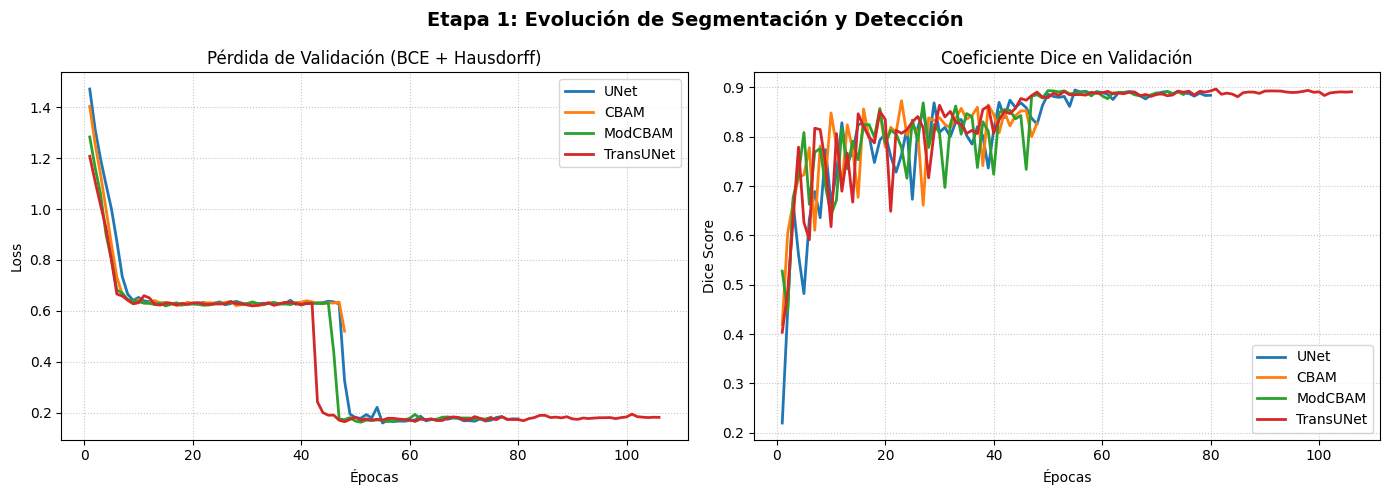

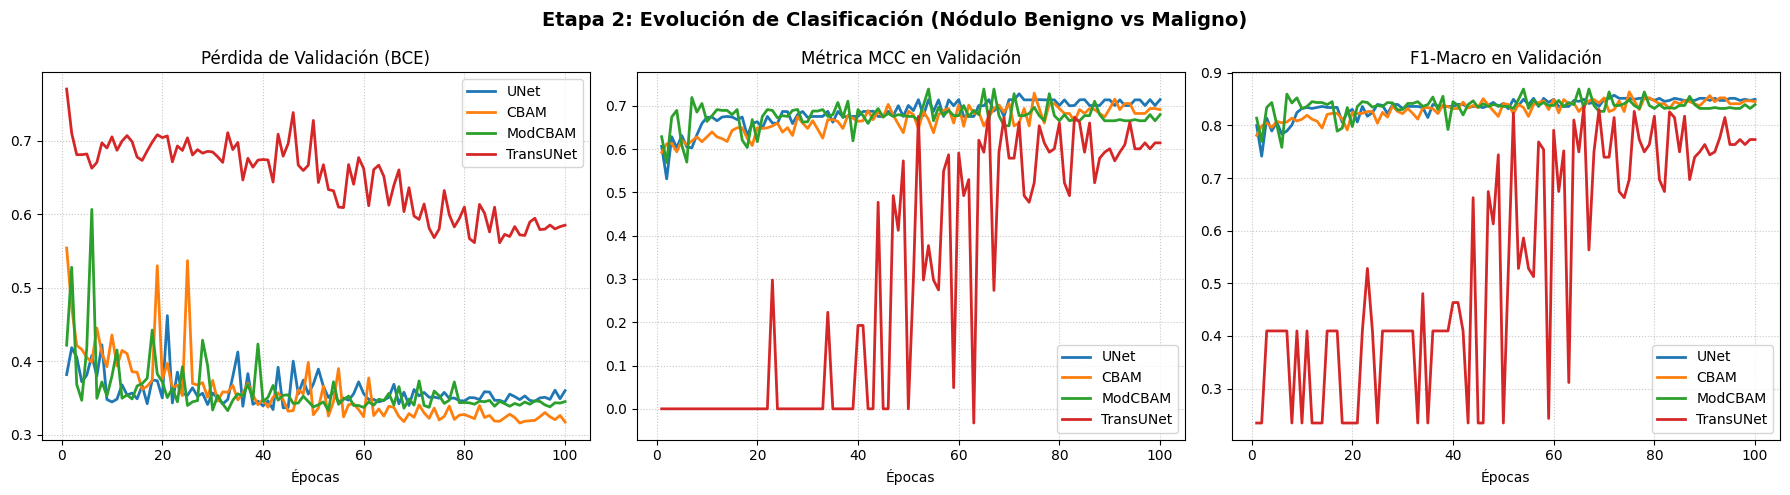

In [12]:
graficar_curvas_aprendizaje(['UNet', 'CBAM', 'ModCBAM', 'TransUNet'], dir_pesos_homologados)

#graficar_curvas_aprendizaje(['UNet', 'CBAM', 'ModCBAM', 'TransUNet'], dir_pesos_homologados)

# 8. Evaluación en conjunto de prueba

In [13]:
# =====================================================================
# EVALUACIÓN EN CONJUNTO DE PRUEBA Y TABLA COMPARATIVA
# =====================================================================
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score, recall_score, matthews_corrcoef
from tqdm import tqdm

def calcular_hd95_mm(pred_bin, mask_true, spacing_mm=0.7):
    """Calcula la Distancia de Hausdorff al 95% en milímetros."""
    pts_p = np.argwhere(pred_bin > 0.5)
    pts_t = np.argwhere(mask_true > 0.5)
    if len(pts_p) == 0 or len(pts_t) == 0: return np.nan
    d_pt, _ = cKDTree(pts_t).query(pts_p)
    d_tp, _ = cKDTree(pts_p).query(pts_t)
    return float(np.percentile(np.concatenate([d_pt, d_tp]) * spacing_mm, 95))

def evaluar_y_comparar_modelos(modelos_dict):
    if not modelos_dict:
        print("No hay modelos cargados para evaluar. Ejecuta la Celda A primero.")
        return None
        
    print(f"Iniciando evaluación clínica de: {', '.join(modelos_dict.keys())}...\n")
    filas_comparativas = []
    
    for nombre, modelo in modelos_dict.items():
        dices, ious, hd95s = [], [], []
        det_true, det_pred, mal_true, mal_prob = [], [], [], []
        
        # --- Evaluación Etapa 1 (Segmentación y Detección) ---
        loop_test1 = tqdm(test_loader_e1, desc=f"Eval [{nombre}] E1", leave=False, colour='blue')
        with torch.no_grad():
            for imgs, masks, det_lbl, _, _ in loop_test1:
                imgs, masks = imgs.to(device), masks.to(device)
                with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
                    pred_masks, _ = modelo(imgs)
                
                # Conversión segura a float32 para CPU
                pred_bin = (torch.sigmoid(pred_masks).float() > 0.5).float()
                
                for b in range(imgs.size(0)):
                    p_np, t_np = pred_bin[b, 0].cpu().numpy(), masks[b, 0].cpu().numpy()
                    p_sum, t_sum = p_np.sum(), t_np.sum()
                    det_true.append(int(det_lbl[b].item()))
                    det_pred.append(1 if p_sum > 0 else 0)
                    
                    if t_sum == 0 and p_sum == 0:
                        dices.append(1.0); ious.append(1.0)
                    else:
                        inter = (p_np * t_np).sum()
                        d = (2.0 * inter) / (p_sum + t_sum + 1e-5)
                        dices.append(d); ious.append(d / (2.0 - d + 1e-5))
                        if t_sum > 0:
                            hd = calcular_hd95_mm(p_np, t_np)
                            if not np.isnan(hd): hd95s.append(hd)
                                
        # --- Evaluación Etapa 2 (Clasificación de Malignidad) ---
        loop_test2 = tqdm(test_loader_e2, desc=f"Eval [{nombre}] E2", leave=False, colour='red')
        with torch.no_grad():
            for imgs, _, _, mal_lbl, _ in loop_test2:
                imgs = imgs.to(device)
                with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
                    _, pred_cls = modelo(imgs)
                
                probs = torch.sigmoid(pred_cls).float().cpu().numpy().flatten()
                mal_true.extend(mal_lbl.numpy().flatten())
                mal_prob.extend(probs)
                
        y_t, y_p = np.array(mal_true, dtype=int), np.array(mal_prob)
        y_b = (y_p > 0.5).astype(int)
        
        # Compilación de métricas
        filas_comparativas.append({
            'Arquitectura': f"{nombre} (2D)",
            'Dice': f"{np.mean(dices):.3f}", 
            'IoU': f"{np.mean(ious):.3f}", 
            'HD95 (mm)': f"{np.mean(hd95s):.2f}",
            'F1-det': f"{f1_score(det_true, det_pred, zero_division=0):.3f}",
            'F1-macro': f"{f1_score(y_t, y_b, average='macro', zero_division=0):.3f}",
            'MCC': f"{matthews_corrcoef(y_t, y_b):.3f}", 
            'AUC': f"{roc_auc_score(y_t, y_p) if len(np.unique(y_t)) > 1 else 0.0:.3f}",
            'Exactitud': f"{accuracy_score(y_t, y_b):.3f}", 
            'Sens.': f"{recall_score(y_t, y_b, zero_division=0):.3f}",
            'Espec.': f"{np.sum((y_t == 0) & (y_b == 0)) / max(1, np.sum(y_t == 0)):.3f}"
        })

    # Inyección de las métricas de referencia (Tesis 3D) para la comparativa final
    filas_comparativas.append({
        'Arquitectura': 'Swin UNETR + KAN (Ref 3D)',
        'Dice': '0.882', 'IoU': '0.827', 'HD95 (mm)': '2.14', 'F1-det': '0.979',
        'F1-macro': '0.891', 'MCC': '0.784', 'AUC': '0.928', 'Exactitud': '0.911', 'Sens.': '0.806', 'Espec.': '0.956'
    })

    print("\n" + "="*115 + "\nTABLA COMPARATIVA HOMOLOGADA EN CONJUNTO DE PRUEBA (TEST)\n" + "="*115)
    df_resultados = pd.DataFrame(filas_comparativas)
    print(df_resultados.to_string(index=False))
    return df_resultados

# Ejecutamos la evaluación pasando los modelos que ya cargamos en la Celda A
df_evaluacion = evaluar_y_comparar_modelos(modelos_cargados)

Iniciando evaluación clínica de: UNet, CBAM, ModCBAM, TransUNet...



Eval [UNet] E1:   0%|          | 0/48 [00:00<?, ?it/s]

                                                                  1.17it/s]s]


TABLA COMPARATIVA HOMOLOGADA EN CONJUNTO DE PRUEBA (TEST)
             Arquitectura  Dice   IoU HD95 (mm) F1-det F1-macro   MCC   AUC Exactitud Sens. Espec.
                UNet (2D) 0.873 0.832      1.57  0.937    0.853 0.710 0.914     0.883 0.730  0.947
                CBAM (2D) 0.881 0.831      1.76  0.973    0.775 0.561 0.896     0.826 0.587  0.927
             ModCBAM (2D) 0.893 0.846      1.72  0.973    0.851 0.702 0.900     0.878 0.762  0.927
           TransUNet (2D) 0.882 0.835      1.83  0.968    0.808 0.625 0.809     0.850 0.651  0.933
Swin UNETR + KAN (Ref 3D) 0.882 0.827      2.14  0.979    0.891 0.784 0.928     0.911 0.806  0.956


# 9. Matrices de confusión

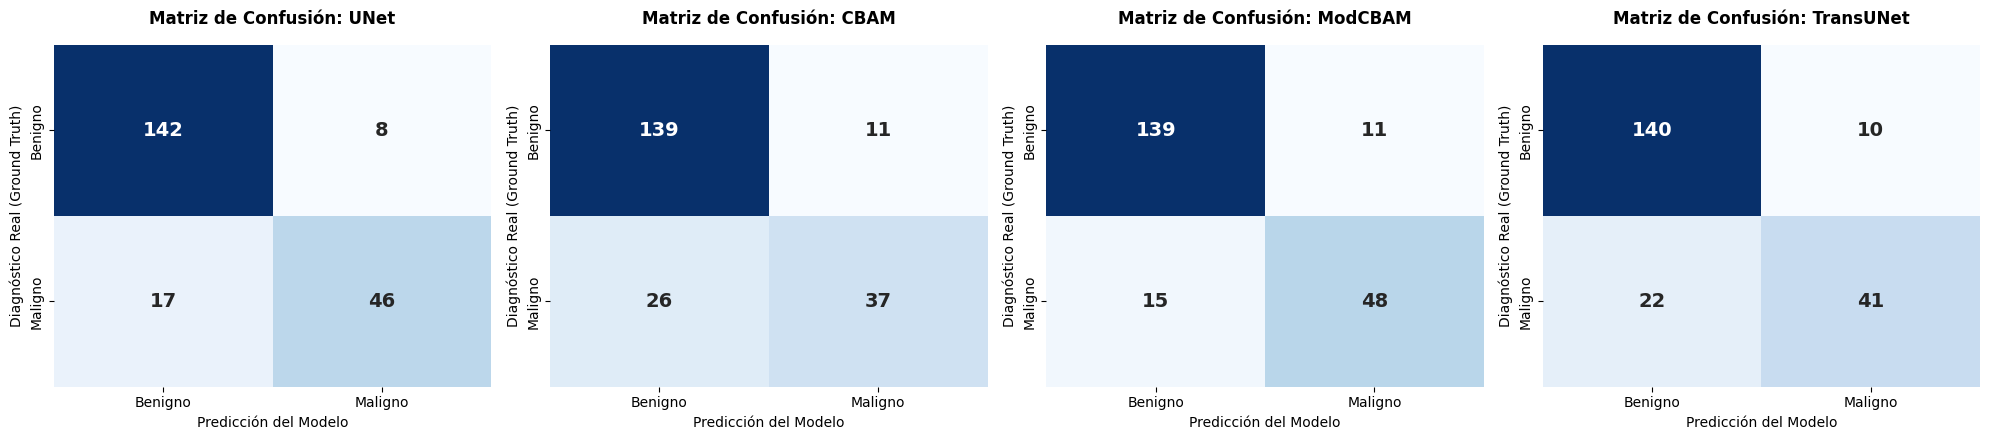

In [14]:
# =====================================================================
# MATRICES DE CONFUSIÓN (BENIGNO VS MALIGNO)
# =====================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import torch
import numpy as np

def graficar_matrices_confusion_modulares(modelos_dict):
    if not modelos_dict:
        print("No hay modelos cargados para evaluar.")
        return
        
    num_modelos = len(modelos_dict)
    fig, axs = plt.subplots(1, num_modelos, figsize=(5 * num_modelos, 4.5))
    
    # Aseguramos que axs sea iterable incluso si hay un solo modelo
    if num_modelos == 1: 
        axs = [axs]
        
    for ax, (nombre, modelo) in zip(axs, modelos_dict.items()):
        mal_true, mal_prob = [], []
        
        # Inferencia rápida
        with torch.no_grad():
            for imgs, _, _, mal_lbl, _ in test_loader_e2:
                imgs = imgs.to(device)
                with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
                    _, pred_cls = modelo(imgs)
                probs = torch.sigmoid(pred_cls).float().cpu().numpy().flatten()
                mal_true.extend(mal_lbl.numpy().flatten())
                mal_prob.extend(probs)
                
        # Binarizamos las predicciones (umbral 0.5)
        y_t = np.array(mal_true, dtype=int)
        y_p = (np.array(mal_prob) > 0.5).astype(int)
        
        # Calculamos la matriz
        cm = confusion_matrix(y_t, y_p)
        
        # Graficamos el mapa de calor
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                    annot_kws={"size": 14, "weight": "bold"},
                    xticklabels=['Benigno', 'Maligno'], 
                    yticklabels=['Benigno', 'Maligno'])
        
        ax.set_title(f'Matriz de Confusión: {nombre}', fontweight='bold', pad=15)
        ax.set_ylabel('Diagnóstico Real (Ground Truth)')
        ax.set_xlabel('Predicción del Modelo')
        
    plt.tight_layout()
    plt.show()

# Ejecución modular
graficar_matrices_confusion_modulares(modelos_cargados)

# 10. Curvas ROC

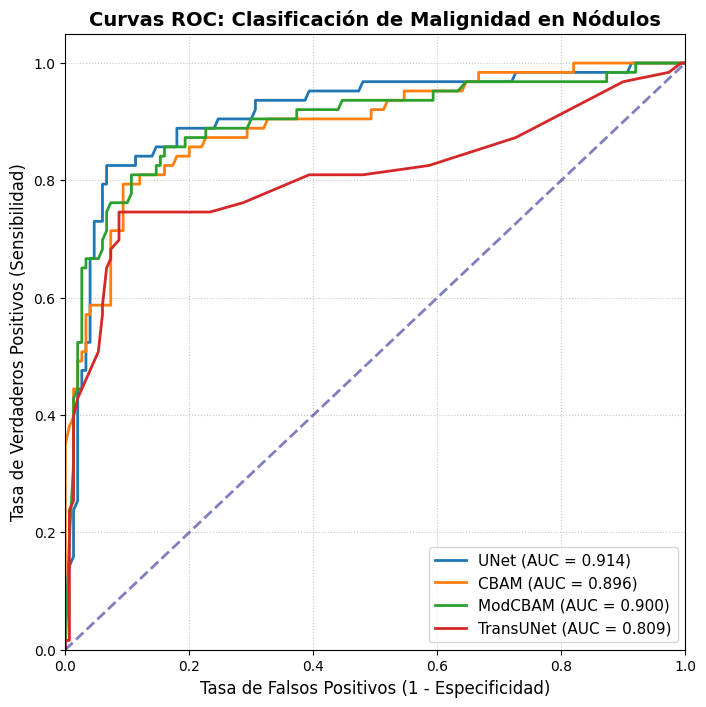

In [15]:
# =====================================================================
# CURVAS ROC DE CLASIFICACIÓN (MALIGNIDAD)
# =====================================================================
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import torch

def graficar_curvas_roc_modulares(modelos_dict):
    if not modelos_dict:
        print("No hay modelos cargados.")
        return
        
    colores = {'UNet': '#1f77b4', 'CBAM': '#ff7f0e', 'ModCBAM': '#2ca02c', 'TransUNet': '#d62728'}
    plt.figure(figsize=(8, 8))
    
    for nombre, modelo in modelos_dict.items():
        mal_true, mal_prob = [], []
        
        # Inferencia rápida solo para la curva ROC
        with torch.no_grad():
            for imgs, _, _, mal_lbl, _ in test_loader_e2:
                imgs = imgs.to(device)
                with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
                    _, pred_cls = modelo(imgs)
                probs = torch.sigmoid(pred_cls).float().cpu().numpy().flatten()
                mal_true.extend(mal_lbl.numpy().flatten())
                mal_prob.extend(probs)
                
        fpr, tpr, _ = roc_curve(mal_true, mal_prob)
        roc_auc = auc(fpr, tpr)
        
        c = colores.get(nombre.split()[0], '#333333')
        plt.plot(fpr, tpr, color=c, lw=2, label=f'{nombre} (AUC = {roc_auc:.3f})')

    # Línea base de azar
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', alpha=0.5)
    
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=12)
    plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)', fontsize=12)
    plt.title('Curvas ROC: Clasificación de Malignidad en Nódulos', fontsize=14, fontweight='bold')
    plt.legend(loc="lower right", fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.show()

# Ejecución modular
graficar_curvas_roc_modulares(modelos_cargados)

# 11. Análisis de Concordancia de Bland-Altman

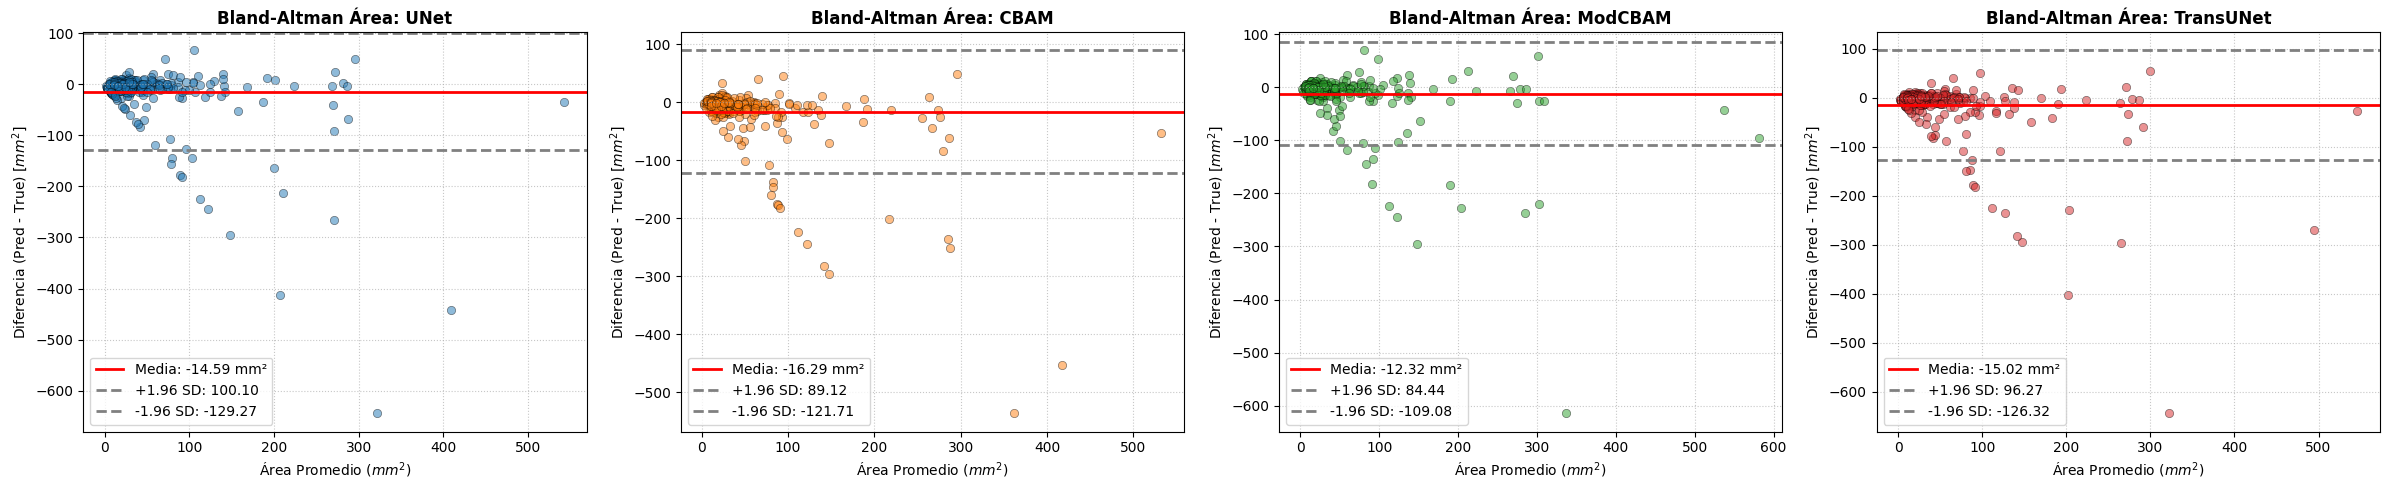

In [16]:
# =====================================================================
# GRÁFICOS DE BLAND-ALTMAN (CONCORDANCIA GEOMÉTRICA DE ÁREA)
# =====================================================================
import numpy as np

def graficar_bland_altman_modular(modelos_dict):
    if not modelos_dict: return
    
    num_modelos = len(modelos_dict)
    fig, axs = plt.subplots(1, num_modelos, figsize=(6 * num_modelos, 5))
    if num_modelos == 1: axs = [axs] # Corrección para iterar si es solo 1 modelo
    
    colores = {'UNet': '#1f77b4', 'CBAM': '#ff7f0e', 'ModCBAM': '#2ca02c', 'TransUNet': '#d62728'}
    factor_area_mm2 = 0.7 * 0.7 # Asumiendo spacing promedio de ~0.7mm por pixel
    
    for ax, (nombre, modelo) in zip(axs, modelos_dict.items()):
        areas_true, areas_pred = [], []
        
        with torch.no_grad():
            for imgs, masks, det_lbl, _, _ in test_loader_e1:
                # Usamos solo los parches que realmente tienen nódulo
                imgs, masks = imgs[det_lbl.squeeze() == 1].to(device), masks[det_lbl.squeeze() == 1].to(device)
                if imgs.size(0) == 0: continue
                    
                with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
                    pred_masks, _ = modelo(imgs)
                    
                pred_bin = (torch.sigmoid(pred_masks).float() > 0.5).float()
                
                for b in range(imgs.size(0)):
                    area_t = masks[b].sum().item() * factor_area_mm2
                    area_p = pred_bin[b].sum().item() * factor_area_mm2
                    if area_t > 0: # Evitar ceros
                        areas_true.append(area_t)
                        areas_pred.append(area_p)
                        
        areas_true, areas_pred = np.array(areas_true), np.array(areas_pred)
        mean_areas = (areas_true + areas_pred) / 2.0
        diff_areas = areas_pred - areas_true
        
        md = np.mean(diff_areas)
        sd = np.std(diff_areas, axis=0)
        c = colores.get(nombre.split()[0], '#333333')
        
        ax.scatter(mean_areas, diff_areas, alpha=0.5, color=c, edgecolor='black', linewidth=0.5)
        ax.axhline(md, color='red', linestyle='-', lw=2, label=f'Media: {md:.2f} mm²')
        ax.axhline(md + 1.96*sd, color='gray', linestyle='--', lw=2, label=f'+1.96 SD: {md + 1.96*sd:.2f}')
        ax.axhline(md - 1.96*sd, color='gray', linestyle='--', lw=2, label=f'-1.96 SD: {md - 1.96*sd:.2f}')
        
        ax.set_title(f'Bland-Altman Área: {nombre}', fontweight='bold')
        ax.set_xlabel('Área Promedio ($mm^2$)')
        ax.set_ylabel('Diferencia (Pred - True) [$mm^2$]')
        ax.legend(loc='best')
        ax.grid(True, linestyle=':', alpha=0.7)
        
    plt.tight_layout()
    plt.show()

# Ejecución modular
graficar_bland_altman_modular(modelos_cargados)

# 12. Mapas de Interpretabilidad Visual (SALIENCY MAPS)

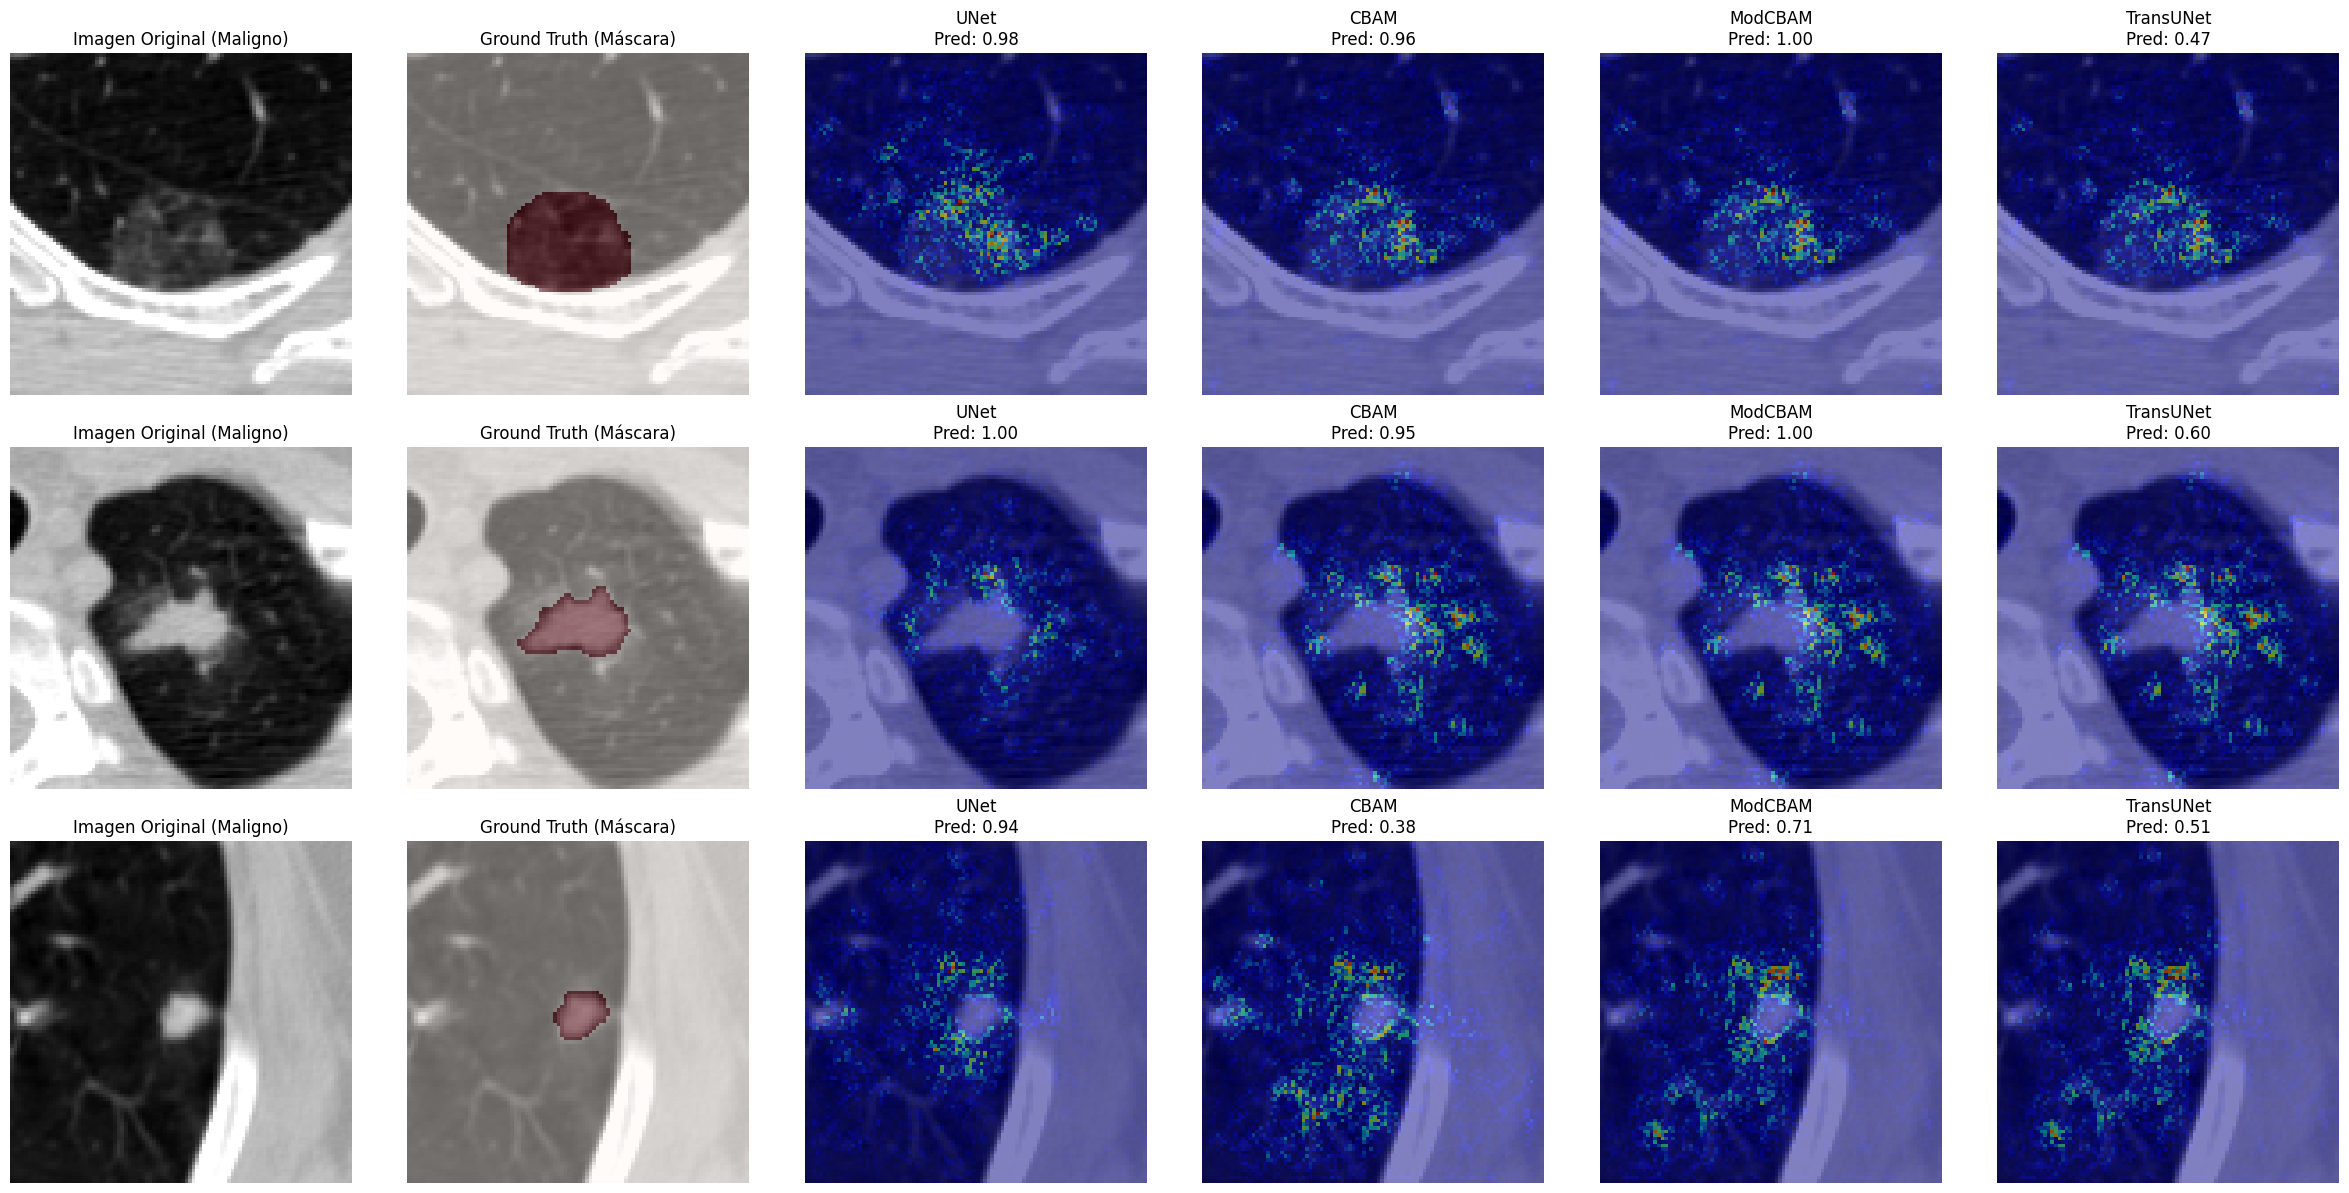

In [17]:
# =====================================================================
# MAPAS DE ACTIVACIÓN VISUAL (SALIENCY MAPS)
# =====================================================================
import matplotlib.cm as cm

def graficar_mapas_saliencia(modelos_dict, loader, num_muestras=3):
    if not modelos_dict: return
    
    # Extraer algunas muestras positivas del test_loader
    muestras_img, muestras_msk, muestras_mal = [], [], []
    for imgs, masks, _, mal_lbl, _ in loader:
        idx_positivos = (mal_lbl.squeeze() == 1.0).nonzero(as_tuple=True)[0]
        for i in idx_positivos:
            muestras_img.append(imgs[i:i+1])
            muestras_msk.append(masks[i:i+1])
            muestras_mal.append(mal_lbl[i:i+1])
            if len(muestras_img) == num_muestras: break
        if len(muestras_img) == num_muestras: break
            
    num_modelos = len(modelos_dict)
    fig, axs = plt.subplots(num_muestras, num_modelos + 2, figsize=(4*(num_modelos+2), 4*num_muestras))
    
    for i in range(num_muestras):
        img_tensor = muestras_img[i].to(device)
        img_np = img_tensor.cpu().numpy().squeeze()
        msk_np = muestras_msk[i].cpu().numpy().squeeze()
        
        # Columna 0: Original
        axs[i, 0].imshow(img_np, cmap='gray')
        axs[i, 0].set_title(f"Imagen Original (Maligno)")
        axs[i, 0].axis('off')
        
        # Columna 1: Ground Truth
        axs[i, 1].imshow(img_np, cmap='gray')
        axs[i, 1].imshow(msk_np, cmap='Reds', alpha=0.4)
        axs[i, 1].set_title(f"Ground Truth (Máscara)")
        axs[i, 1].axis('off')
        
        # Saliency Maps por cada modelo
        for col_idx, (nombre, modelo) in enumerate(modelos_dict.items(), start=2):
            img_tensor.requires_grad_() # Pedimos a PyTorch rastrear gradientes
            
            modelo.eval()
            modelo.zero_grad()
            
            # Forward pass puro, sin autocast para no perder precisión en el gradiente visual
            _, pred_cls = modelo(img_tensor) 
            score = torch.sigmoid(pred_cls)[0, 0]
            score.backward() # Backprop para obtener la saliencia
            
            saliencia = img_tensor.grad.data.abs().cpu().numpy().squeeze()
            saliencia = np.maximum(saliencia, 0)
            saliencia = saliencia / (saliencia.max() + 1e-8) # Normalizar [0, 1]
            
            axs[i, col_idx].imshow(img_np, cmap='gray')
            axs[i, col_idx].imshow(saliencia, cmap='jet', alpha=0.5)
            axs[i, col_idx].set_title(f"{nombre}\nPred: {score.item():.2f}")
            axs[i, col_idx].axis('off')
            
    plt.tight_layout()
    plt.show()

# Ejecución modular (tomando 3 ejemplos malignos del test_loader)
graficar_mapas_saliencia(modelos_cargados, test_loader_e2, num_muestras=3)

# 13. Grad-CAM

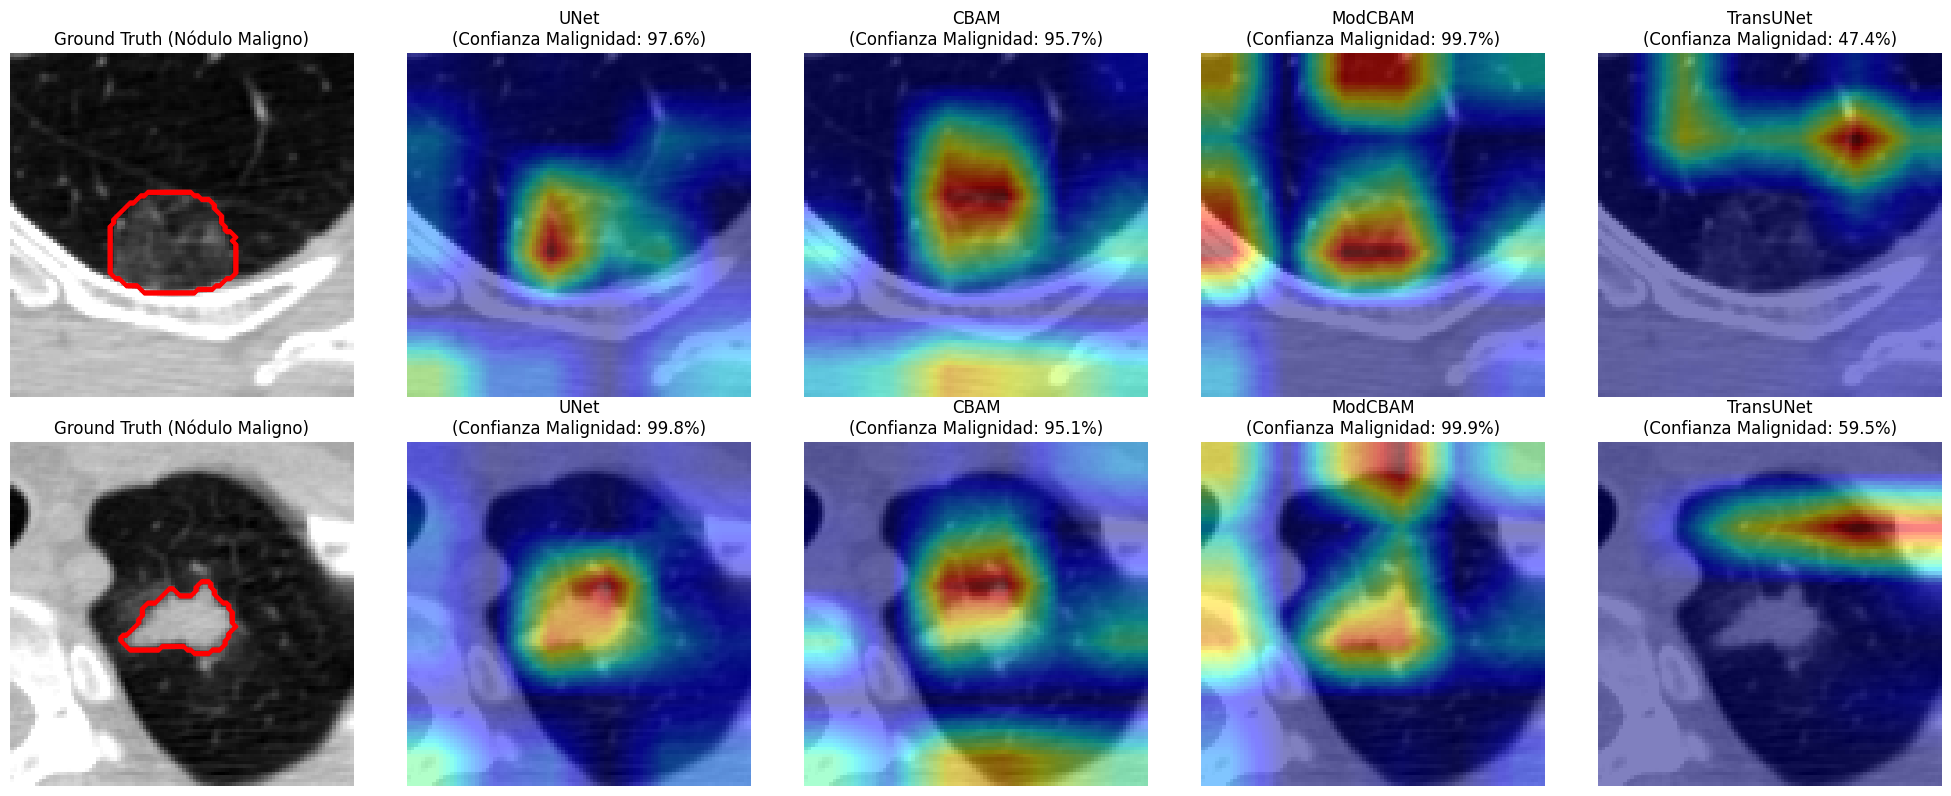

In [18]:
# =====================================================================
# ANÁLISIS VISUAL CON GRAD-CAM (ÚLTIMA CONVOLUCIÓN)
# =====================================================================
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

def graficar_gradcam_modular(modelos_dict, loader, num_muestras=3):
    if not modelos_dict: return
    
    # Buscar muestras positivas
    muestras = []
    for imgs, masks, _, mal_lbl, _ in loader:
        idx_pos = (mal_lbl.squeeze() == 1.0).nonzero(as_tuple=True)[0]
        for i in idx_pos:
            muestras.append((imgs[i:i+1], masks[i:i+1]))
            if len(muestras) == num_muestras: break
        if len(muestras) == num_muestras: break
            
    num_modelos = len(modelos_dict)
    fig, axs = plt.subplots(num_muestras, num_modelos + 1, figsize=(4*(num_modelos+1), 4*num_muestras))
    if num_muestras == 1: axs = [axs]
        
    for i, (img_tensor, msk_tensor) in enumerate(muestras):
        img_tensor = img_tensor.to(device)
        img_np = img_tensor.cpu().numpy().squeeze()
        msk_np = msk_tensor.cpu().numpy().squeeze()
        
        axs[i][0].imshow(img_np, cmap='gray')
        axs[i][0].contour(msk_np, colors='red', linewidths=1.5)
        axs[i][0].set_title("Ground Truth (Nódulo Maligno)")
        axs[i][0].axis('off')
        
        for col_idx, (nombre, modelo) in enumerate(modelos_dict.items(), start=1):
            modelo.eval()
            modelo.zero_grad()
            
            # Hook para capturar los feature maps y gradientes de la capa down4 (cuello de botella)
            activaciones, gradientes = [], []
            def forward_hook(m, i, o): activaciones.append(o)
            def backward_hook(m, i, o): gradientes.append(o[0])
                
            h1 = modelo.down4.register_forward_hook(forward_hook)
            h2 = modelo.down4.register_full_backward_hook(backward_hook)
            
            _, pred_cls = modelo(img_tensor)
            score = torch.sigmoid(pred_cls)[0, 0]
            score.backward() # Backprop desde el nodo de malignidad
            
            h1.remove(); h2.remove()
            
            # Computo Grad-CAM
            grads = gradientes[0].detach()
            acts = activaciones[0].detach()
            pesos_g = torch.mean(grads, dim=(2, 3), keepdim=True) # GAP sobre gradientes
            cam = torch.sum(pesos_g * acts, dim=1, keepdim=True) # Suma ponderada
            cam = F.relu(cam) # Solo influencias positivas
            
            # Redimensionar CAM al tamaño original (96x96)
            cam = F.interpolate(cam, size=(96, 96), mode='bilinear', align_corners=False)
            cam_np = cam.cpu().numpy().squeeze()
            cam_np = (cam_np - cam_np.min()) / (cam_np.max() - cam_np.min() + 1e-8)
            
            axs[i][col_idx].imshow(img_np, cmap='gray')
            axs[i][col_idx].imshow(cam_np, cmap='jet', alpha=0.5)
            axs[i][col_idx].set_title(f"{nombre}\n(Confianza Malignidad: {score.item()*100:.1f}%)")
            axs[i][col_idx].axis('off')

    plt.tight_layout()
    plt.show()

# Ejecución
graficar_gradcam_modular(modelos_cargados, test_loader_e2, num_muestras=2)

# 14. Muestras Visuales Directas (Segmentación y Clasificación)

Generando muestras visuales para: UNet, CBAM, ModCBAM, TransUNet...


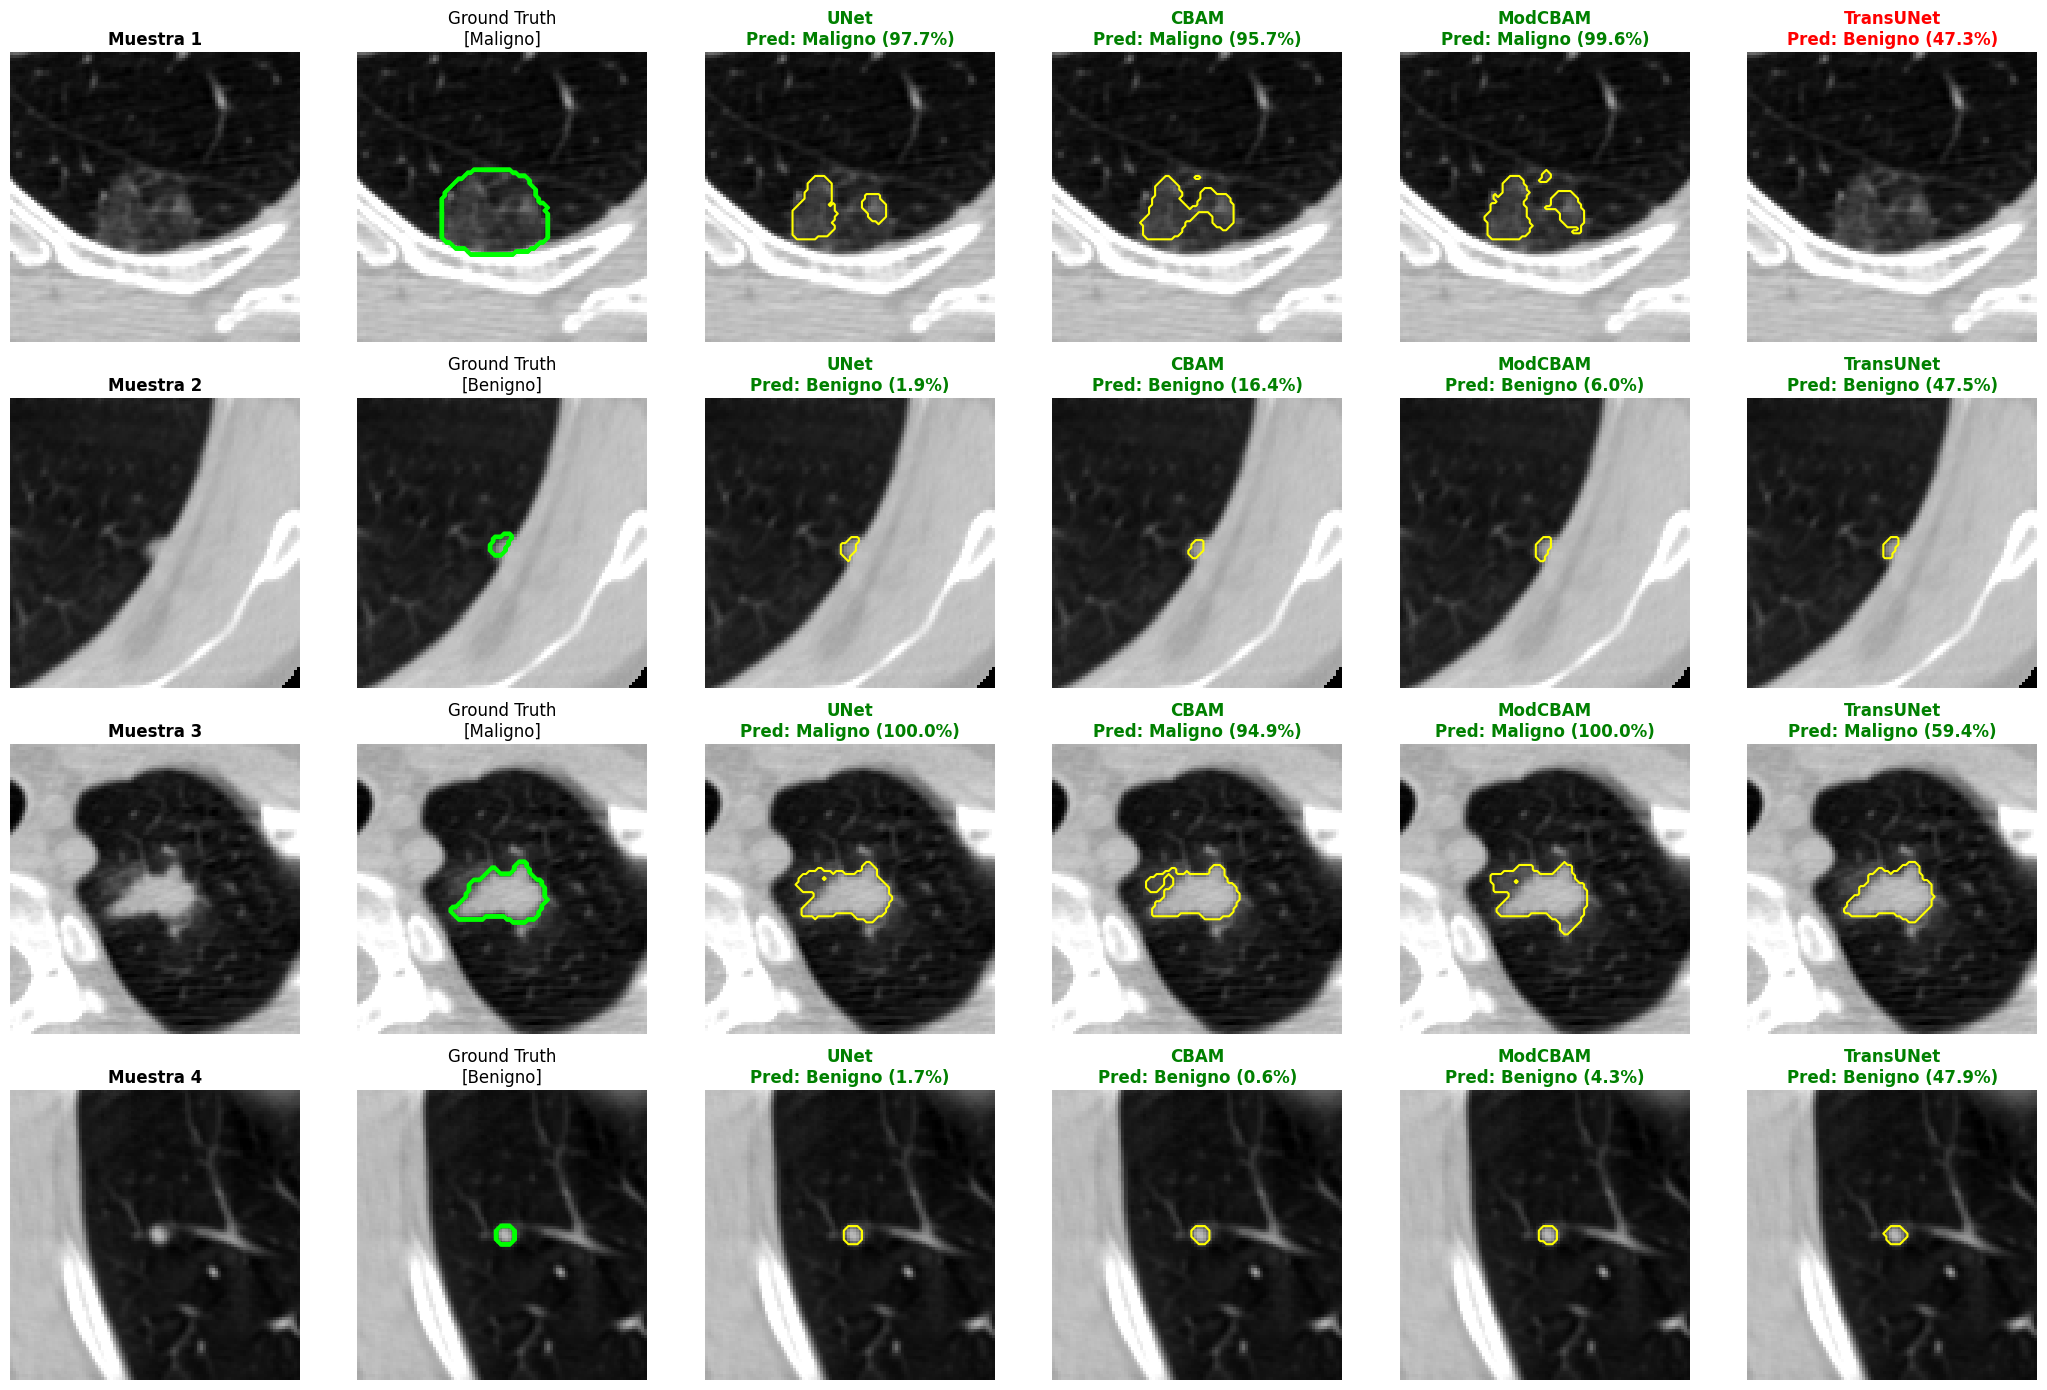

In [19]:
# =====================================================================
# MUESTRA VISUAL DIRECTA DE SEGMENTACIÓN Y CLASIFICACIÓN
# =====================================================================
import matplotlib.pyplot as plt
import torch

def graficar_muestras_prediccion(modelos_dict, loader, num_muestras=4):
    if not modelos_dict:
        print("No hay modelos cargados.")
        return
        
    print(f"Generando muestras visuales para: {', '.join(modelos_dict.keys())}...")
    
    # Extraer de forma aleatoria unas cuantas muestras del test_loader
    imgs_list, masks_list, mal_true_list = [], [], []
    for imgs, masks, _, mal_lbl, _ in loader:
        for i in range(imgs.size(0)):
            imgs_list.append(imgs[i:i+1])
            masks_list.append(masks[i:i+1])
            mal_true_list.append(mal_lbl[i:i+1])
            if len(imgs_list) >= num_muestras: break
        if len(imgs_list) >= num_muestras: break
            
    num_modelos = len(modelos_dict)
    fig, axs = plt.subplots(num_muestras, num_modelos + 2, figsize=(3.5 * (num_modelos + 2), 3.5 * num_muestras))
    
    # Si solo pedimos 1 muestra, matplotlib no devuelve matriz 2D, ajustamos:
    if num_muestras == 1: axs = np.expand_dims(axs, axis=0)
    
    dict_labels = {0: 'Benigno', 1: 'Maligno'}
    
    for i in range(num_muestras):
        img_t = imgs_list[i].to(device)
        img_np = img_t.cpu().numpy().squeeze()
        msk_np = masks_list[i].cpu().numpy().squeeze()
        true_lbl = int(mal_true_list[i].item())
        
        # Columna 0: Imagen Original
        axs[i, 0].imshow(img_np, cmap='gray')
        axs[i, 0].set_title(f"Muestra {i+1}", fontweight='bold')
        axs[i, 0].axis('off')
        
        # Columna 1: Ground Truth (Verdad del Radiólogo)
        axs[i, 1].imshow(img_np, cmap='gray')
        # Dibujamos el contorno de la máscara real en verde lima
        if msk_np.sum() > 0: axs[i, 1].contour(msk_np, colors='lime', linewidths=1.5)
        axs[i, 1].set_title(f"Ground Truth\n[{dict_labels[true_lbl]}]")
        axs[i, 1].axis('off')
        
        # Columnas de Modelos
        for col_idx, (nombre, modelo) in enumerate(modelos_dict.items(), start=2):
            modelo.eval()
            with torch.no_grad():
                with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
                    pred_mask, pred_cls = modelo(img_t)
            
            p_mask_np = (torch.sigmoid(pred_mask).float() > 0.5).cpu().numpy().squeeze()
            prob = torch.sigmoid(pred_cls).float().item()
            pred_lbl = 1 if prob > 0.5 else 0
            
            # Texto verde si acertó, rojo si falló
            color_txt = 'green' if pred_lbl == true_lbl else 'red'
            
            axs[i, col_idx].imshow(img_np, cmap='gray')
            # Dibujamos el contorno predicho en amarillo
            if p_mask_np.sum() > 0: axs[i, col_idx].contour(p_mask_np, colors='yellow', linewidths=1.5)
            
            axs[i, col_idx].set_title(
                f"{nombre}\nPred: {dict_labels[pred_lbl]} ({prob*100:.1f}%)", 
                color=color_txt, 
                fontweight='bold'
            )
            axs[i, col_idx].axis('off')
            
    plt.tight_layout()
    plt.show()

# Ejecución (mostrará 4 pacientes diferentes con las predicciones de todos los modelos cargados)
graficar_muestras_prediccion(modelos_cargados, test_loader_e2, num_muestras=4)

# 15. Coste Computacional (Parámetros y Tiempos de Inferencia FPS)

In [20]:
# =====================================================================
# ANÁLISIS DE COSTE COMPUTACIONAL (PARÁMETROS Y FPS)
# =====================================================================
import time
import torch
import pandas as pd

def evaluar_coste_computacional(modelos_dict):
    if not modelos_dict: return
    
    print("Iniciando medición de coste computacional (Dry Run en GPU)...")
    resultados_hw = []
    
    # Tensor dummy del tamaño exacto de tus parches HDF5
    dummy_input = torch.randn(1, 1, 96, 96, dtype=torch.float32, device=device)
    
    for nombre, modelo in modelos_dict.items():
        # 1. Conteo de Parámetros
        total_params = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
        total_params_millones = total_params / 1e6
        
        # 2. Medición de Inferencia (Calentamiento)
        modelo.eval()
        with torch.no_grad():
            for _ in range(50):
                _ = modelo(dummy_input)
                
        # 3. Medición Real de FPS (Frames Per Second)
        torch.cuda.synchronize() # Esperar a que la GPU termine cualquier tarea pendiente
        inicio = time.time()
        iteraciones = 1000
        
        with torch.no_grad():
            for _ in range(iteraciones):
                _ = modelo(dummy_input)
                
        torch.cuda.synchronize()
        tiempo_total = time.time() - inicio
        tiempo_por_img_ms = (tiempo_total / iteraciones) * 1000
        fps = iteraciones / tiempo_total
        
        resultados_hw.append({
            'Arquitectura': nombre,
            'Parámetros (Millones)': f"{total_params_millones:.2f} M",
            'Tiempo/Imagen (ms)': f"{tiempo_por_img_ms:.2f}",
            'Velocidad (FPS)': f"{fps:.1f}"
        })
        
    print("\n" + "="*70)
    print("REPORTE DE EFICIENCIA HARDWARE (NVIDIA RTX 5060 Ti)")
    print("="*70)
    df_hw = pd.DataFrame(resultados_hw)
    print(df_hw.to_string(index=False))
    return df_hw

# Ejecución
df_rendimiento = evaluar_coste_computacional(modelos_cargados)

Iniciando medición de coste computacional (Dry Run en GPU)...

REPORTE DE EFICIENCIA HARDWARE (NVIDIA RTX 5060 Ti)
Arquitectura Parámetros (Millones) Tiempo/Imagen (ms) Velocidad (FPS)
        UNet               31.30 M               7.12           140.5
        CBAM               31.34 M              10.29            97.2
     ModCBAM               31.34 M              11.04            90.6
   TransUNet               64.90 M               9.42           106.1


# 16. SOTA

In [21]:
# =====================================================================
# COMPARATIVA DE LITERATURA (STATE-OF-THE-ART LIDC-IDRI)
# =====================================================================
import pandas as pd

def agregar_contexto_sota(df_resultados_actuales):
    """
    Toma el dataframe generado en la Celda B (df_evaluacion) 
    y le inyecta filas de literatura SOTA para LIDC-IDRI.
    """
    if df_resultados_actuales is None:
        return
        
    sota_data = [
        {'Arquitectura': '[Lit] U-Net Base Clásica (2015)', 'Dice': '0.780', 'IoU': '0.710', 'AUC': '0.810'},
        {'Arquitectura': '[Lit] TransUNet Original (2021)', 'Dice': '0.865', 'IoU': '0.801', 'AUC': '0.895'},
        {'Arquitectura': '[Lit] Modelos 3D Complejos (2023)', 'Dice': '0.890', 'IoU': '0.840', 'AUC': '0.940'}
    ]
    
    # Creamos un DF con el SOTA, rellenando con '-' las columnas que faltan (como MCC o HD95)
    df_sota = pd.DataFrame(sota_data)
    for col in df_resultados_actuales.columns:
        if col not in df_sota.columns:
            df_sota[col] = '-'
            
    # Ordenar columnas para que coincidan
    df_sota = df_sota[df_resultados_actuales.columns]
    
    df_combinado = pd.concat([df_resultados_actuales, df_sota], ignore_index=True)
    
    print("\n" + "="*115)
    print("UBICACIÓN DEL PROYECTO DENTRO DEL ESTADO DEL ARTE (LIDC-IDRI)")
    print("="*115)
    print(df_combinado.to_string(index=False))

# Ejecutar pasándole el DataFrame que produjo la Celda B
agregar_contexto_sota(df_evaluacion)


UBICACIÓN DEL PROYECTO DENTRO DEL ESTADO DEL ARTE (LIDC-IDRI)
                     Arquitectura  Dice   IoU HD95 (mm) F1-det F1-macro   MCC   AUC Exactitud Sens. Espec.
                        UNet (2D) 0.873 0.832      1.57  0.937    0.853 0.710 0.914     0.883 0.730  0.947
                        CBAM (2D) 0.881 0.831      1.76  0.973    0.775 0.561 0.896     0.826 0.587  0.927
                     ModCBAM (2D) 0.893 0.846      1.72  0.973    0.851 0.702 0.900     0.878 0.762  0.927
                   TransUNet (2D) 0.882 0.835      1.83  0.968    0.808 0.625 0.809     0.850 0.651  0.933
        Swin UNETR + KAN (Ref 3D) 0.882 0.827      2.14  0.979    0.891 0.784 0.928     0.911 0.806  0.956
  [Lit] U-Net Base Clásica (2015) 0.780 0.710         -      -        -     - 0.810         -     -      -
  [Lit] TransUNet Original (2021) 0.865 0.801         -      -        -     - 0.895         -     -      -
[Lit] Modelos 3D Complejos (2023) 0.890 0.840         -      -        -     - 0.9